# 🤖 Camera-Based Obstacle Detection and Avoidance for Autonomous Warehouse Robots

### Group 3 · Image and Scene Recognition

A mobile robot must drive **from a start point to a goal** inside a warehouse.
On its way there are workers, forklifts, pallets, shiny stretch-wrapped
pallets and fallen objects nobody told it about. The robot only has a
**camera** (colour image + depth image). It has to **see** the obstacles,
**understand** how far away they are, and **decide** how to drive around them
without crashing.

In this notebook we walk through the whole system, from the pixels to the
steering decision. Every step runs live, so you can see each part working.

> **The simulation in this notebook is built from real warehouse photos.**
> The robot's camera view is put together from real photographs of racks,
> floors, walls, workers, forklifts and parcels taken from the datasets our
> detector was trained on. The robot really runs the trained YOLO11n detector
> on every frame.

## 📖 How to use this notebook (for the presenter)

* Run the cells **from top to bottom** (`Shift + Enter`), or use
  *Kernel → Restart & Run All* before class. Everything takes about 3 minutes
  on a normal laptop, without a GPU.
* Every **code cell** has a cell right above it, starting with
  **👇 What the code below does**. Read that cell to the class first, then run
  the code.
* Inside every code cell, **each line of code has a comment** (`# ...`)
  right above it that says what that line does, so you can walk
  through the code line by line.
* Other text cells help with teaching:

| Cell marker | Meaning |
|---|---|
| 🎯 **Learning goals** | what the class should understand after the section |
| 🧠 **Concept** | the idea behind the next step, in plain words |
| 🧮 **The math** | the formula, if you want to go deeper |
| 🔎 **What to notice** | what to point at in the output |
| ❓ **Ask the class** | a question to keep students thinking |
| ✅ **Recap** | a short summary of the section |

## 🗺️ Lesson plan

| # | Section | Main idea |
|---|---|---|
| 1 | The problem | why warehouse robots need vision |
| 2 | System architecture | the whole pipeline at a glance |
| 3 | Setup | load the project code |
| 4 | The warehouse world | a simulation built for learning and testing |
| 5 | A camera made of real photos | pinhole camera, RGB + depth images |
| 6 | Object detection (YOLO11n) | letterbox, IoU, non-maximum suppression, training more |
| 7 | Depth-image processing | background subtraction against the map |
| 8 | Sensor fusion | from pixels to metres; unknown obstacles |
| 9 | Video processing: tracking | Kalman filter, track IDs, velocity |
| 10 | The obstacle map | the 47 numbers the robot's brain reads |
| 11 | Reinforcement learning (PPO) | how the robot learned to drive |
| 12 | Safety shield | rules that can override the AI |
| 13 | One full drive | everything working together |
| 14 | Evaluation | how good is it, in numbers |
| 15 | Limitations and future work | what still fails, honestly |
| 16 | Summary and discussion | |

---
# 1. The problem

🎯 **Learning goals:** understand *what* the robot must do and *why* it is hard.

Warehouses are busy places:

| Obstacle | Why it is difficult |
|---|---|
| 👷 **Workers** | they move, they step out from behind racks, and they must be protected most |
| 🚜 **Forklifts** | large and fast moving vehicles |
| 📦 **Pallets / parcels** | they stand in the aisle, often where the map says it is free |
| ✨ **Stretch-wrapped pallets** | the shiny plastic film confuses depth sensors (reflections) |
| ❓ **Fallen / unknown objects** | traffic cones, tool cases… things the detector was **never trained on** |

The robot knows the **map** of the warehouse (where the racks and walls are),
but **none of the obstacles above are on the map**. It must discover them with
its camera, while it is moving.

🧠 **Concept: two kinds of "seeing"**

1. **Recognition** (*what is it?*) → an **object detector** looks at the colour
   image and says "this box is a person, 80 % sure".
2. **Geometry** (*where is it, how far?*) → a **depth image** gives the distance
   of every pixel, so we can also find things the detector does not know.

A good robot needs **both**. The detector alone misses unknown objects; depth
alone does not know that a person needs a bigger safety distance than a box.

❓ **Ask the class:** *Why should a robot keep a larger distance from a person
than from a pallet?*

---
# 2. System architecture

```
                ┌────────────────────────────────────────────────────────────┐
  Camera        │  RGB image (640 × 384)          Depth image (metres)       │
  (real photos) └───────────────┬───────────────────────────┬────────────────┘
                                │                           │
                     ① YOLO11n detector            ② Depth processing
                     person / forklift /           map background subtraction,
                     package boxes                 foreground mask, range scan
                                │                           │
                                └─────────► ③ Fusion ◄──────┘
                                   box → metres, gates, unknown obstacles
                                             │
                                   ④ Tracking (video processing)
                                   Kalman filter on the floor plane
                                             │
                                   ⑤ Obstacle map: 47 numbers
                                             │
                                   ⑥ PPO policy (reinforcement learning)
                                   GO / SLOW / STOP / TURN_LEFT / TURN_RIGHT
                                             │
                                   ⑦ Safety shield (rules can override)
                                             │
                                          Motors
```

Each numbered box is one section of this notebook.

📚 **Glossary (words we will use)**

| Word | Meaning |
|---|---|
| **Bounding box** | rectangle around a detected object: (x1, y1, x2, y2) in pixels |
| **Confidence** | how sure the detector is (0 – 1) |
| **IoU** | *Intersection over Union*: how much two boxes overlap |
| **NMS** | *Non-Maximum Suppression*: removes duplicate boxes |
| **Depth image** | an image where each pixel stores a distance in metres |
| **Foreground** | pixels that belong to something that is *not* on the map |
| **Kalman filter** | an algorithm that tracks a moving object through noisy measurements |
| **Policy** | the robot's "brain": state → action |
| **PPO** | *Proximal Policy Optimization*, the reinforcement-learning algorithm we used |
| **Held-out data** | data never used for training, used only for testing (honest evaluation) |

---
# 3. Setup

🎯 **Learning goals:** load the project code so the notebook can use it.

The project code lives in the folder `src/`. This notebook lives in
`notebooks/`, so we first find the project folder and tell Python where it is.

**👇 What the code below does**

* Searches for the project folder (the one that contains `src/`), starting
  from where the notebook is.
* On **Google Colab** it downloads the project from GitHub and installs the
  requirements first, so the notebook also works in the browser.
* Changes the working directory to the project folder and adds it to
  `sys.path`, so `import src...` works.

In [1]:
# Standard library: operating-system helpers (we use it to change folder)
import os
# Standard library: run shell commands (used for "git clone" on Colab)
import subprocess
# Standard library: information about Python itself (module search path)
import sys
# Path objects make folder handling easy on Windows, macOS and Linux
from pathlib import Path

# Address of the project on GitHub (used only on Google Colab)
REPO_URL = "https://github.com/stevenkayitaresteven/warehouse-obstacle-detection.git"


# Function: walk up from a folder until we find the project folder
def find_project_root(start):
    # Check the folder itself and then every parent folder above it
    for folder in [start, *start.parents]:
        # The project folder is the one that contains src/simulation/warehouse_env.py
        if (folder / "src" / "simulation" / "warehouse_env.py").exists():
            # Found it: give this folder back
            return folder
    # Not found anywhere above us
    return None


# Where the project will be if we download (clone) it on Colab
CLONE = Path.cwd() / "warehouse-obstacle-detection"
# Look for the project above the current folder, or in the clone folder
ROOT = find_project_root(Path.cwd()) or find_project_root(CLONE)
# Not found, but we are running on Google Colab: download and install it
if ROOT is None and "google.colab" in sys.modules:
    # Download (clone) the project from GitHub
    subprocess.run(["git", "clone", "-q", REPO_URL, str(CLONE)], check=True)
    # The project folder is now the downloaded copy
    ROOT = CLONE
    # Install the project's requirements plus matplotlib (for the plots)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt"), "matplotlib"], check=True)
# Still not found: stop with a clear message
if ROOT is None:
    # Tell the presenter how to open the notebook correctly
    raise RuntimeError("Please open this notebook from the project folder (warehouse-obstacle-detection/notebooks/).")

# Make the project folder the working folder (so relative paths like "assets/..." work)
os.chdir(ROOT)
# Only if Python cannot yet find the project's own modules ...
if str(ROOT) not in sys.path:
    # ... put the project folder first in the module search path (so "import src..." works)
    sys.path.insert(0, str(ROOT))
# Show which folder we are using
print("Project folder:", ROOT)

Project folder: /home/user/warehouse-obstacle-detection


**👇 What the code below does**

Checks that every library we need is installed and prints its version.
If something is missing, it prints the exact `pip install` command to run.

* `numpy`: arrays and maths
* `opencv` (`cv2`): image processing
* `onnxruntime`: runs the YOLO11n detector (no PyTorch, no GPU needed)
* `gymnasium`: the standard interface for reinforcement-learning environments
* `Pillow`, `matplotlib`: loading images and drawing plots

In [2]:
# importlib lets us import a module whose name is given as text
import importlib

# Module name → pip package name, for every library this notebook needs
needed = {"numpy": "numpy", "cv2": "opencv-python-headless", "onnxruntime": "onnxruntime", "gymnasium": "gymnasium", "PIL": "Pillow", "matplotlib": "matplotlib"}
# Here we collect the packages that are not installed
missing = []
# Try every library, one by one
for module, package in needed.items():
    # Try to import it ...
    try:
        # ... by its name
        m = importlib.import_module(module)
        # It worked: print a tick and the version number
        print(f"✓ {module:12s} {getattr(m, '__version__', '')}")
    # The import failed: the library is not installed
    except ImportError:
        # Remember which pip package has to be installed
        missing.append(package)
        # Print a cross
        print(f"✗ {module:12s} MISSING")
# If anything is missing ...
if missing:
    # ... print one pip command that installs all of it
    print("\nPlease run:  pip install " + " ".join(missing))

✓ numpy        2.5.3
✓ cv2          5.0.0
✓ onnxruntime  1.29.0
✓ gymnasium    1.4.0
✓ PIL          12.3.0


✓ matplotlib   3.11.2


**👇 What the code below does**

1. Imports the standard libraries and the **project modules**: the
   simulation, the photo camera, the detector, the perception stack, the
   tracker, the policy and the safety shield.
2. Defines small helper functions: `show()` and `show_row()` display
   images with matplotlib, and `display_fig()` shows a figure as a JPEG
   picture (photos stay sharp while the notebook file stays small). We use
   them in the rest of the notebook.

In [3]:
# Show matplotlib plots inside the notebook
%matplotlib inline
# In-memory files (to build pictures and the GIF without writing to disk)
import io
# Read the saved evaluation results (JSON files)
import json
# Maths functions: sin, cos, tan, radians, hypot ...
import math
# Measure how long things take
import time

# OpenCV: image processing (resize, draw boxes, colour maps, morphology)
import cv2
# Matplotlib: charts and image display
import matplotlib.pyplot as plt
# NumPy: arrays and fast maths on whole images at once
import numpy as np
# Show a picture (JPEG or GIF bytes) directly in the notebook
from IPython.display import Image as IPImage
# Show any object in the notebook output
from IPython.display import display
# Pillow: open the cut-out images and build the GIF animation
from PIL import Image

# Project: the trained PPO policy (runs with NumPy) and the rule-based baseline
from src.navigation.controllers import NumpyPolicy, RuleBasedController
# Project: attach the real-image camera, and draw the perception result on a picture
from src.perception.camera_perception import attach_real_camera, draw_overlay
# Project: the YOLO11n detector (ONNX file) and its helper functions
from src.perception.onnx_detector import CLASS_NAMES, OnnxDetector, box_iou, letterbox, nms
# Project: the Kalman-filter tracker and its detection format
from src.perception.tracking import Detection3D, GroundTracker
# Project: the rule-based safety shield
from src.safety.shield import SafetyShield
# Project: the bank of real photo cut-outs (people, forklifts, parcels, unknown objects)
from src.simulation.photo_camera import SpriteBank
# Project: draw the top-down map, and the full demo picture (map + camera + HUD)
from src.simulation.render import draw_map, render_frame
# Project: the warehouse environment, its settings and its constants
from src.simulation.warehouse_env import ACTIONS, BOX, CATEGORY_NAMES, FORKLIFT, GO, PALLET, PERSON, RACK, STOP, WALL, EnvConfig, Obstacle, WarehouseEnv

# Plot settings: picture resolution and a light grid on charts
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
# Print NumPy numbers with 2 decimals and without scientific notation
np.set_printoptions(precision=2, suppress=True)


# Helper: show a matplotlib figure as a JPEG picture (small file, sharp photo)
def display_fig(fig=None):
    # Use the figure we were given, or else the current one
    fig = fig or plt.gcf()
    # An in-memory file that will hold the JPEG
    buf = io.BytesIO()
    # Save the figure as JPEG into that memory file
    fig.savefig(buf, format="jpeg", bbox_inches="tight", pil_kwargs={"quality": 88})
    # Close the figure so matplotlib does not show it a second time
    plt.close(fig)
    # Show the JPEG in the notebook
    display(IPImage(data=buf.getvalue(), format="jpeg"))


# Helper: show one image (an RGB picture, or a 2-D array drawn with a colour map)
def show(img, title=None, width=12, cmap=None):
    # New figure with the same width/height ratio as the image
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
    # Draw the image
    plt.imshow(img, cmap=cmap)
    # Hide the axes (pixel numbers are not interesting here)
    plt.axis("off")
    # If a title was given ...
    if title:
        # ... write it above the image
        plt.title(title)
    # Display the figure as JPEG
    display_fig()


# Helper: show several images next to each other
def show_row(images, titles=None, width=16, cmaps=None):
    # How many images we have
    n = len(images)
    # One row of n small plot areas
    fig, axes = plt.subplots(1, n, figsize=(width, width / n * 0.75))
    # Make sure "axes" is always a list (also when there is only 1 image)
    axes = np.atleast_1d(axes)
    # Go through the plot areas and the images together
    for i, (ax, img) in enumerate(zip(axes, images)):
        # Draw image i (with its colour map, if one was given)
        ax.imshow(img, cmap=(cmaps[i] if cmaps else None))
        # Hide the axes
        ax.axis("off")
        # If titles were given ...
        if titles:
            # ... write title i above image i
            ax.set_title(titles[i], fontsize=10)
    # Remove extra white space between the images
    plt.tight_layout()
    # Display the figure as JPEG
    display_fig(fig)


# Confirm that everything was loaded
print("Project modules loaded ✓")

Project modules loaded ✓


---
# 4. The warehouse world (simulation)

🎯 **Learning goals:** know what the simulated warehouse contains, and why we
train and test in simulation first.

🧠 **Concept: why a simulation?**

* **Safety:** a learning robot crashes thousands of times. That is fine in
  simulation, not with real people.
* **Unlimited data:** every episode is a new random warehouse.
* **Exact ground truth:** the simulator knows where everything really is,
  so we can *measure* how good the perception is.

Our world follows the **Gymnasium** standard used in reinforcement learning:

```python
obs, info = env.reset()                                   # new warehouse
obs, reward, terminated, truncated, info = env.step(action)   # 0.2 s later
```

**👇 What the code below does**

* Creates a warehouse environment and builds a new random warehouse with
  `reset(seed=7)`. The **seed** makes it repeatable: the same seed always
  gives the same warehouse.
* Prints the most important facts: size of the warehouse, the robot, the
  camera, the five actions, and the obstacles placed in this episode
  (none of them are on the robot's map).

In [4]:
# Default settings of the warehouse (size, robot, camera, rewards ...)
cfg = EnvConfig()
# Create the warehouse environment with those settings
env = WarehouseEnv(cfg)
# Build a new random warehouse; seed 7 makes it the same every time
obs, info = env.reset(seed=7)

# Print the size of the warehouse
print(f"Warehouse size        : {cfg.width:.0f} m x {cfg.height:.0f} m")
# Print how many rack blocks and aisles this layout has
print(f"Racks on the map      : {len(env.racks)} rack blocks, {len(env.aisles)} aisles")
# Print the robot's size, its top speed and the length of one time step
print(f"Robot                 : radius {cfg.robot_radius} m, top speed {cfg.v_max} m/s, one step = {cfg.dt} s")
# Print the camera's field of view, number of distance rays and range
print(f"Camera                : {cfg.fov_deg:.0f}° field of view, {cfg.n_rays} distance rays, range {cfg.max_range:.0f} m")
# Print the five actions the robot can choose from
print(f"Actions               : {ACTIONS}")
# Print how many numbers the robot's state (observation) has
print(f"Observation (state)   : {obs.shape[0]} numbers")
# All obstacles of this episode: the standing ones and the moving ones
objects = env.statics + env.dynamics
# Count the obstacles per category (none of them is on the robot's map)
print("Obstacles NOT on map  :", {CATEGORY_NAMES[c]: sum(o.category == c for o in objects) for c in (PERSON, FORKLIFT, PALLET, BOX)})
# Print where the robot starts and where its goal is
print(f"Start {tuple(round(v, 1) for v in env.start)}  →  goal {tuple(round(float(v), 1) for v in env.goal)}")

Warehouse size        : 24 m x 16 m
Racks on the map      : 7 rack blocks, 4 aisles
Robot                 : radius 0.35 m, top speed 1.5 m/s, one step = 0.2 s
Camera                : 120° field of view, 21 distance rays, range 6 m
Actions               : ['GO', 'SLOW', 'STOP', 'TURN_LEFT', 'TURN_RIGHT']
Observation (state)   : 47 numbers
Obstacles NOT on map  : {'person': 2, 'forklift': 0, 'pallet': 2, 'unknown': 4}
Start (1.8, 5.9)  →  goal (23.0, 10.6)


**👇 What the code below does**

Draws the warehouse **from above** with the project's renderer
(`draw_map`). This bird's-eye view is only for us; the robot never sees
it. The robot only sees its camera image.

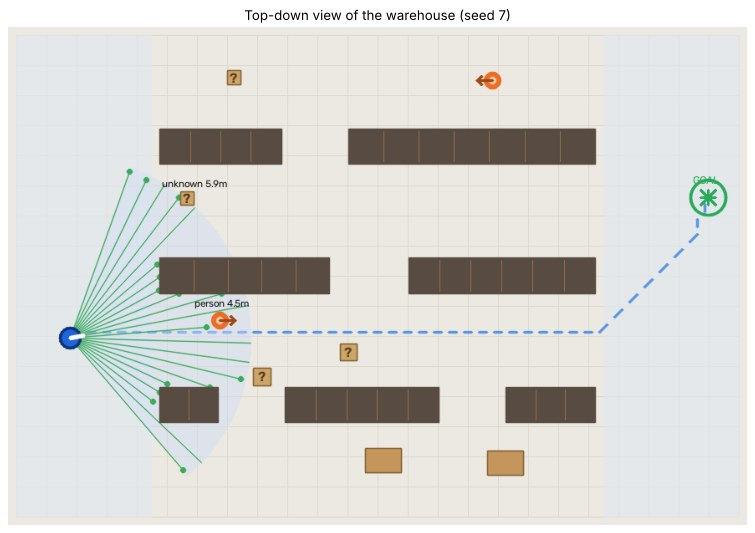

In [5]:
# Draw the top-down map of the warehouse and show it
show(draw_map(env), "Top-down view of the warehouse (seed 7)")

🔎 **What to notice**

* **Dark brown blocks** = racks (on the map). **Blue dashed line** = the
  global path planned on the map, from the robot (blue circle) to the goal
  (green star).
* **Orange dots** = workers, **yellow** = forklifts, **brown/light-blue
  rectangles** = pallets, **"?"** = unknown fallen objects. They are **not**
  on the map, so the planned path can go straight through them. The camera
  has to find them.
* The **light-blue fan** is the camera's 120° field of view, and the **green
  lines** are the 21 distance rays the robot measures.

🧠 **Concept: domain randomisation**

If a robot only ever trains in **one** warehouse, it learns that warehouse
by heart and fails in a new one (*over-fitting*). So every episode changes:
the number of rack rows, the cross-aisles, how many workers and pallets
there are, their speeds, the sensor noise and the detector quality. The robot
has to learn a strategy that works **everywhere**.

**👇 What the code below does**

Builds three different random warehouses (seeds 1, 2 and 3) and shows them
side by side, so you can see the domain randomisation.

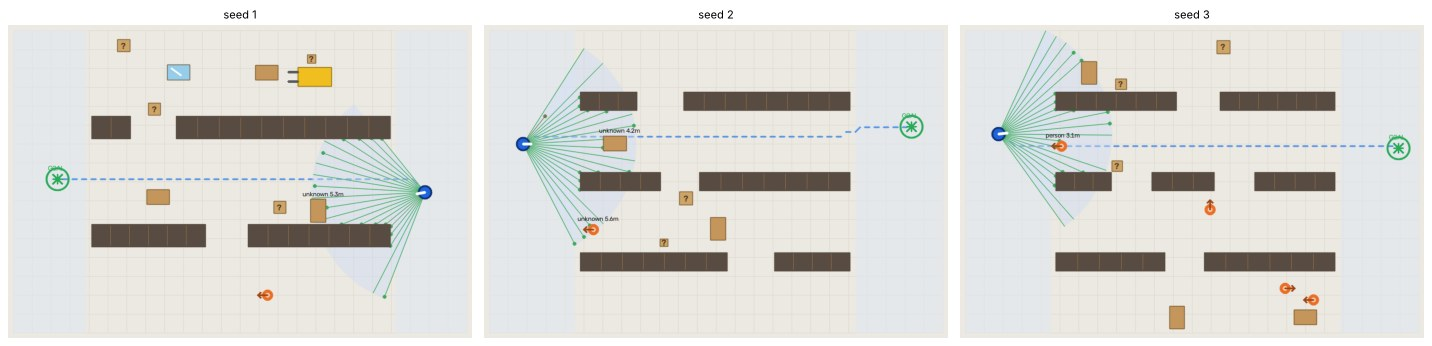

In [6]:
# A list that will hold the three maps
maps = []
# Three different seeds = three different warehouses
for seed in (1, 2, 3):
    # Build a new random warehouse with this seed
    env.reset(seed=seed)
    # Draw its map and keep it
    maps.append(draw_map(env))
# Show the three maps side by side
show_row(maps, [f"seed {s}" for s in (1, 2, 3)], width=18)

✅ **Recap:** the world is a Gymnasium environment. The **map** (racks and
walls) is known; **obstacles are not**. Every episode is a new random
warehouse.

---
# 5. A camera made of real warehouse photos

🎯 **Learning goals:** understand how the robot's camera images are made, and
the **pinhole camera model** that links pixels to metres.

🧠 **Concept**

A simple simulator draws coloured boxes. A detector trained on real photos
would not recognise those boxes. So our camera builds every frame from
**real photo material**:

* **Racks, floor, walls, ceiling** are flat regions of real warehouse photos,
  warped to a front view (*perspective rectification*) and mapped onto the
  3-D geometry with a ray caster.
* **Workers, forklifts, parcels and unknown objects** are **real cut-outs**
  of photos (cut out with a segmentation model or with the dataset's own
  polygons). They stand on the floor at the correct distance and size.

**Honest evaluation:** each cut-out remembers whether its photo was in the
detector's *train*, *val* or *test* split. The robot's camera only uses
**val + test** cut-outs: real people and objects the detector **never saw
during training**.

**👇 What the code below does**

Opens the bank of real cut-outs and counts them per class and per split,
then shows a few **held-out** (val/test) cut-outs of each class on a grey
background.

All cut-outs     : {'person': 148, 'forklift': 37, 'package': 107, 'unknown': 12}
Held-out cut-outs: {'person': 58, 'forklift': 10, 'package': 47, 'unknown': 6}  ← used by the robot's camera


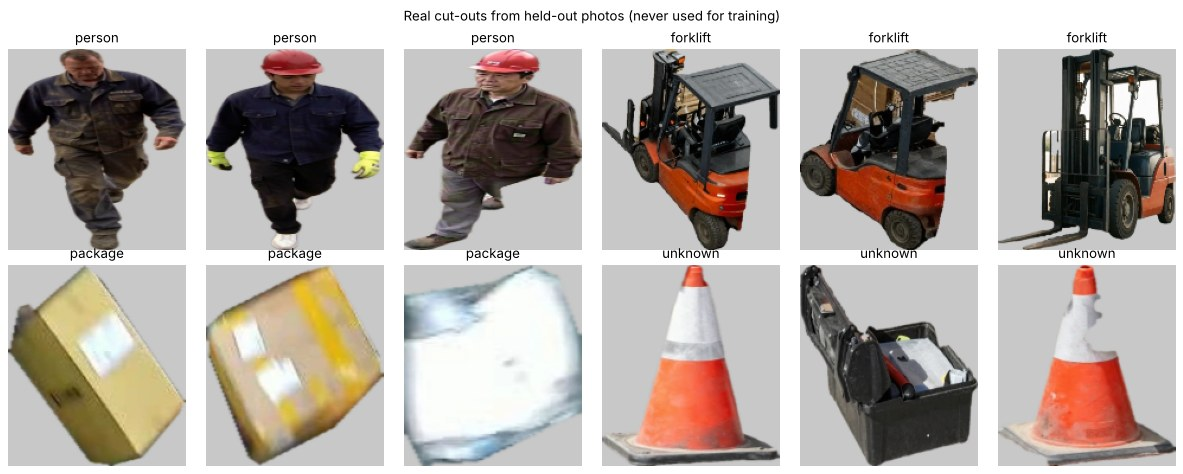

In [7]:
# All cut-outs (from train + val + test photos)
bank_all = SpriteBank(splits=("train", "val", "test"))
# Only the held-out cut-outs (val + test photos): these are used by the robot's camera
bank_test = SpriteBank(splits=("val", "test"))
# Print how many cut-outs exist per class
print("All cut-outs     :", bank_all.counts())
# Print how many held-out cut-outs exist per class
print("Held-out cut-outs:", bank_test.counts(), " ← used by the robot's camera")

# Lists for the small pictures and their titles
tiles, titles = [], []
# Go through the four classes
for cls in ("person", "forklift", "package", "unknown"):
    # Take the first three held-out cut-outs of this class
    for sprite in bank_test.by_class[cls][:3]:
        # Open the cut-out together with its transparency channel (RGBA)
        rgba = np.asarray(Image.open(sprite.path).convert("RGBA"), np.float32)
        # Transparency (alpha) as a number between 0 (see-through) and 1 (solid)
        alpha = rgba[..., 3:] / 255.0
        # Paste the cut-out onto a grey background, using alpha
        tile = rgba[..., :3] * alpha + 200 * (1 - alpha)
        # Resize to a common size so the gallery looks tidy
        tile = cv2.resize(tile.astype(np.uint8), (150, 170))
        # Keep the picture
        tiles.append(tile)
        # Keep its class name as the title
        titles.append(cls)
# A grid of 2 rows x 6 columns
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
# Put each picture into one cell of the grid
for ax, tile, t in zip(axes.ravel(), tiles, titles):
    # Draw the picture
    ax.imshow(tile)
    # Write its class above it
    ax.set_title(t)
    # Hide the axes
    ax.axis("off")
# A title for the whole gallery
plt.suptitle("Real cut-outs from held-out photos (never used for training)")
# Remove extra white space
plt.tight_layout()
# Display the gallery
display_fig(fig)

**👇 What the code below does**

Shows four of the real photo **textures** the camera uses for the static
world: a rack face, the floor, a wall with a dock door, and the ceiling.

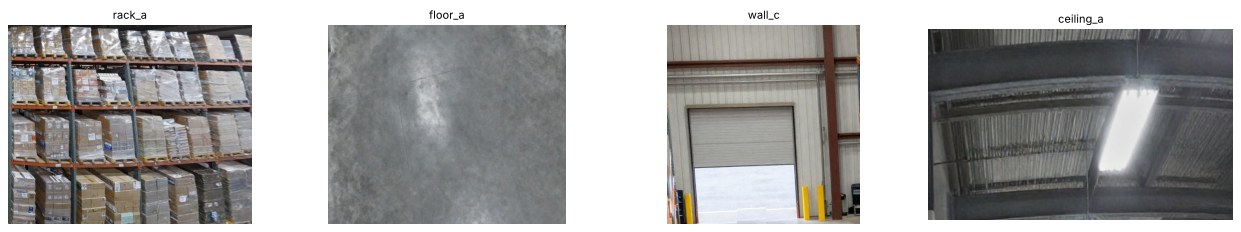

In [8]:
# The four texture files we want to show
names = ["rack_a", "floor_a", "wall_c", "ceiling_a"]
# Read each texture; [:, :, ::-1] turns OpenCV's BGR colour order into RGB
textures = [cv2.imread(f"assets/sim/textures/{n}.jpg")[:, :, ::-1] for n in names]
# Show them side by side
show_row(textures, names, width=16)

🧮 **The math: the pinhole camera model**

A camera maps a 3-D point to a pixel. For our forward-looking camera
(image width $W = 640$ px, field of view $120°$):

$$f = \frac{W/2}{\tan(\text{FOV}/2)} = \frac{320}{\tan 60°} \approx 184.8 \text{ px}
\qquad\text{(focal length in pixels)}$$

A point at distance $z$ (forward) and lateral offset $x$ (left) appears in
column

$$u = c_x - f\,\frac{x}{z}$$

The camera is mounted $h = 0.6$ m above the floor, and the horizon is at row
$c_y$. A point **on the floor** at distance $z$ appears in row

$$v = c_y + f\,\frac{h}{z} \quad\Longleftrightarrow\quad
\boxed{\,z = \frac{f\,h}{v - c_y}\,}$$

So **where an object touches the floor in the image tells us its distance**,
even without a depth sensor. We use this later as a second distance
measurement.

**👇 What the code below does**

Computes the focal length $f$ for our camera and uses the floor formula to
print in which image row the floor appears at 1, 2, 3, 4 and 6 metres.

In [9]:
# Camera settings: image width and height (px), field of view (degrees), height above the floor (m), horizon position
W, H, FOV, CAM_H, HORIZON = 640, 384, 120.0, 0.6, 0.40
# Focal length in pixels: f = (W / 2) / tan(FOV / 2)
f = (W / 2) / math.tan(math.radians(FOV) / 2)
# The image row of the horizon
cy = HORIZON * H
# Print both values
print(f"focal length f = {f:.1f} px, horizon row cy = {cy:.1f}")
# Try a few distances along the floor
for z in (1, 2, 3, 4, 6):
    # Pinhole model: the image row where the floor at distance z appears
    v = cy + f * CAM_H / z
    # Print the row, and turn the row back into a distance to check the formula
    print(f"floor at {z} m  →  image row v = {v:6.1f}  → back to distance: f*h/(v-cy) = {f * CAM_H / (v - cy):.2f} m")

focal length f = 184.8 px, horizon row cy = 153.6
floor at 1 m  →  image row v =  264.5  → back to distance: f*h/(v-cy) = 1.00 m
floor at 2 m  →  image row v =  209.0  → back to distance: f*h/(v-cy) = 2.00 m
floor at 3 m  →  image row v =  190.6  → back to distance: f*h/(v-cy) = 3.00 m
floor at 4 m  →  image row v =  181.3  → back to distance: f*h/(v-cy) = 4.00 m
floor at 6 m  →  image row v =  172.1  → back to distance: f*h/(v-cy) = 6.00 m


🔎 **What to notice:** near objects touch the floor **low** in the image
(large row number); far objects touch it close to the horizon. One pixel of
error matters little near the robot but a lot far away, so the floor-contact
distance gets less accurate with distance.

### Building our demonstration scene

For the next sections we build one **fixed scene** so that everybody sees the
same picture: the robot looks down an aisle with

* a **worker** about 3 m ahead (slightly left),
* a **pallet with parcels** about 5 m ahead (right),
* a **fallen object of unknown type** about 2 m ahead (right). The detector
  has **no class** for it.

**👇 What the code below does**

1. Loads the YOLO11n detector (explained in the next section).
2. Creates an **empty** warehouse (no random obstacles), with the real-image
   camera attached (`attach_real_camera`) and warehouse look **"b"**.
3. Defines `place()`, which puts an obstacle at a given distance ahead
   (`forward`) and to the side (`left`) of the robot.
4. Places the worker, the pallet and the unknown object, then lets the
   perception run for 3 frames (`env._perceive()` renders the camera image
   and processes it without moving the robot).

In [10]:
# Load the YOLO11n detector (explained in the next section)
detector = OnnxDetector()


# Function: an empty warehouse with the real-image camera attached
def make_scene_env(style="b", seed=7):
    # Settings with no random obstacles (we place our own) and no fake shadows
    cfg = EnvConfig(n_workers=(0, 0), n_forklifts=(0, 0), n_pallets=(0, 0), n_boxes=(0, 0), shadow_prob=(0.0, 0.0))
    # Create the environment
    env = WarehouseEnv(cfg)
    # Attach the camera built from real photos (warehouse look "b") and the detector
    attach_real_camera(env, detector=detector, style=style)
    # Build the warehouse layout (seed 7 = the same layout every time)
    env.reset(seed=seed)
    # Turn the robot so it looks straight down the aisle
    env.theta = 0.0
    # Give the ready environment back
    return env


# Function: place an obstacle "forward" metres ahead of the robot and "left" metres to its left
def place(env, category, forward, left, uid, **kw):
    # Cosine and sine of the robot's heading
    ct, st = math.cos(env.theta), math.sin(env.theta)
    # Turn (forward, left) in the robot's frame into a world x coordinate ...
    x = env.x + ct * forward - st * left
    # ... and a world y coordinate
    y = env.y + st * forward + ct * left
    # A person is a circle with a radius of 0.28 m
    if category == PERSON:
        # Create the worker
        obj = Obstacle(PERSON, x, y, radius=0.28, uid=uid, **kw)
    # A pallet is a 1.2 m x 0.8 m rectangle
    elif category == PALLET:
        # Create the pallet (half sizes 0.6 m and 0.4 m)
        obj = Obstacle(PALLET, x, y, 0.6, 0.4, uid=uid, **kw)
    # Anything else is an unknown object (BOX) of 0.6 m x 0.6 m
    else:
        # Create the unknown object (half size 0.3 m)
        obj = Obstacle(BOX, x, y, 0.3, 0.3, uid=uid, **kw)
    # Add it to the warehouse (it is NOT on the robot's map)
    env.statics.append(obj)
    # Give it back, in case we want to change it later
    return obj


# Build our demonstration scene
scene = make_scene_env()
# A worker 3.2 m ahead, 0.5 m to the left
place(scene, PERSON, 3.2, 0.5, uid=901)
# A pallet 5 m ahead, 0.7 m to the right
place(scene, PALLET, 5.0, -0.7, uid=902)
# An unknown fallen object 2.2 m ahead, 0.6 m to the right
place(scene, BOX, 2.2, -0.6, uid=903)
# Run camera + perception 3 times without moving (tracks need a few frames to confirm)
for _ in range(3):
    # Render one camera frame and process it
    scene._perceive()
# The latest camera frame (RGB image, depth image, and the ground truth)
frame = scene.frame
# Print the size and number type of the colour image
print("RGB image  :", frame.rgb.shape, frame.rgb.dtype)
# Print the size, number type and value range of the depth image
print("Depth image:", frame.depth.shape, frame.depth.dtype, f"(metres, {frame.depth.min():.2f} – {frame.depth.max():.1f})")

RGB image  : (384, 640, 3) uint8
Depth image: (384, 640) float32 (metres, 0.42 – 24.3)


**👇 What the code below does**

Shows what the robot's camera sees:

* left: the **RGB image**, made from real photos;
* middle: the **depth image** (bright = near, dark = far);
* right: the **ground truth** from the simulator (green boxes). Only the
  evaluation uses it; the robot never sees it.

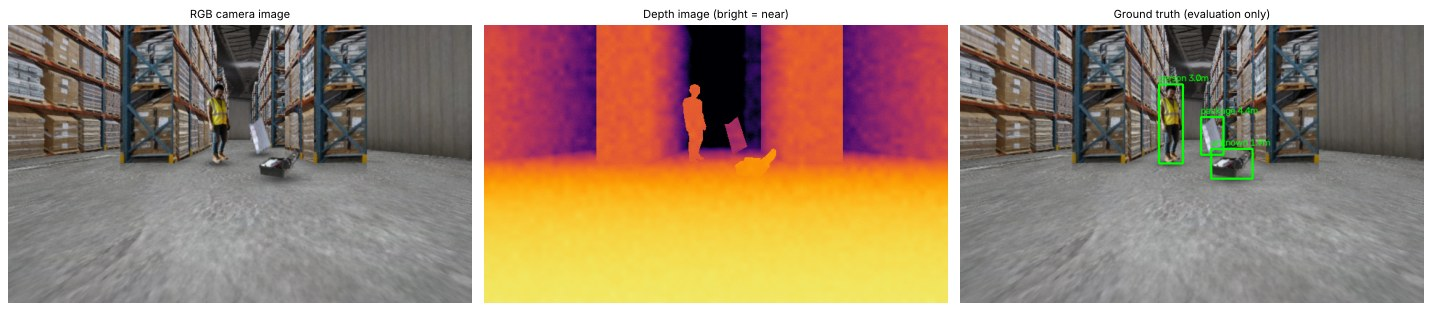

In [11]:
# "Nearness": 1 for very close, 0 for 8 m or farther
near = 1.0 - np.clip(frame.depth / 8.0, 0, 1)
# Turn nearness into a colour picture (bright = near)
depth_vis = cv2.applyColorMap((near * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)[:, :, ::-1]
# Copy the RGB image so we can draw the ground truth on it
gt_vis = frame.rgb.copy()
# Go through every object the simulator says is visible
for g in frame.gt:
    # Its true box, in pixels
    x1, y1, x2, y2 = [int(v) for v in g["bbox"]]
    # Draw the box in green
    cv2.rectangle(gt_vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
    # Write its class and true distance above the box
    cv2.putText(gt_vis, f"{g['class_name']} {g['range']:.1f}m", (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)
# Show the three pictures side by side
show_row([frame.rgb, depth_vis, gt_vis], ["RGB camera image", "Depth image (bright = near)", "Ground truth (evaluation only)"], width=18)

🔎 **What to notice**

* The image looks like a real warehouse because it **is** made from real
  photos.
* In the depth image the three obstacles are brighter (nearer) than the
  floor and racks behind them.
* The depth image has **noise** (grain, like a real depth sensor).
  Section 7 shows how we deal with it.

✅ **Recap:** the camera gives two images per frame: **RGB** (for
recognition) and **depth** (for geometry). The pinhole model connects pixels
and metres.

---
# 6. Object detection with YOLO11n

🎯 **Learning goals:** understand what a one-stage detector does, plus the
three classic tricks around it: **letterbox**, **IoU** and **NMS**.

🧠 **Concept**

**YOLO** (*You Only Look Once*) looks at the whole image **once** and predicts,
for a grid of locations, a box and a score for each class. We use
**YOLO11n**, the smallest ("nano") version, so it runs in real time on a
normal CPU.

Our detector knows **3 classes**: `person`, `forklift`, `package`. It started
from a model pre-trained on COCO (everyday photos) and was **fine-tuned**
(transfer learning) on 1,699 warehouse and industrial photos. For the robot's
camera it was fine-tuned once more, for **8 epochs**, on *robot-view* frames
made only from **training** cut-outs (results at the end of this section).

We run it from an **ONNX** file with `onnxruntime`, so no PyTorch and no GPU
are needed.

**👇 What the code below does**

Loads the detector information: the network input size, the class names,
the engine that runs it, and some metadata stored inside the ONNX file
(model description and export date).

In [12]:
# onnxruntime runs the neural network stored in the ONNX file
import onnxruntime as ort

# Size of the network's input image (height, width)
print("Input size (h, w):", detector.size)
# The three classes the detector knows
print("Classes          :", detector.names)
# Which engine runs the network
print("Runs with        :", detector.backend)
# Open the ONNX file once more, to read the information stored inside it
meta = ort.InferenceSession(str(detector.path), providers=["CPUExecutionProvider"]).get_modelmeta()
# Print the model description written when the model was exported
print("Model            :", meta.custom_metadata_map.get("description"))
# Print the export date
print("Exported         :", meta.custom_metadata_map.get("date", "")[:10])

Input size (h, w): (384, 640)
Classes          : ('person', 'forklift', 'package')
Runs with        : onnxruntime
Model            : Ultralytics YOLO11n model trained on /home/user/warehouse-obstacle-detection/datasets/processed/data_v2.yaml
Exported         : 2026-11-16


🧠 **Concept: letterbox pre-processing**

The network expects a fixed input size (384 × 640). Photos come in many
sizes. If we simply stretched them, people would look fat or thin and the
detector would get worse. **Letterbox** = resize while **keeping the aspect
ratio**, then fill the rest with grey bars, like a widescreen film on an old
TV.

**👇 What the code below does**

Loads a real warehouse photo (2048 × 1360 pixels), runs `letterbox()` to
bring it to the network size 384 × 640, and shows both. The function also
returns the scale factor and the padding, which we need later to map the
boxes back to the original photo.

original 2048x1360 → network input 640x384; scale 0.282, padding left 31px, top 0px


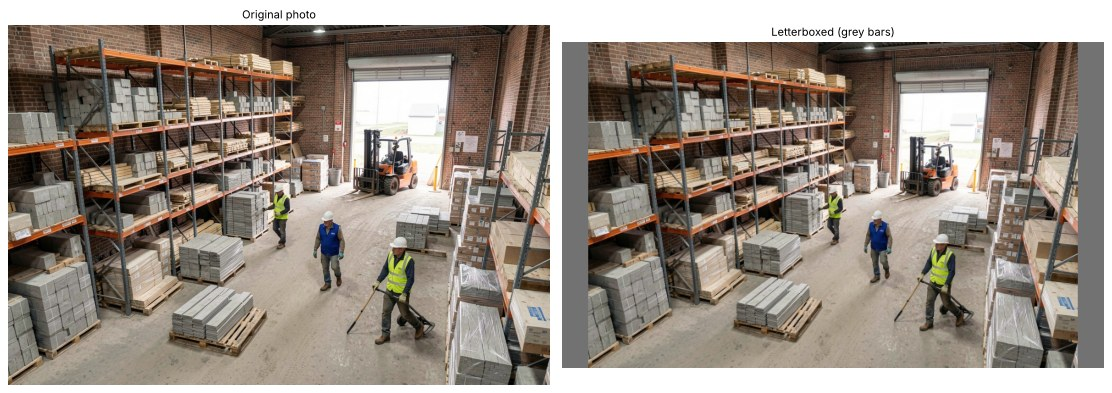

In [13]:
# Read a real warehouse photo ([:, :, ::-1] turns BGR into RGB)
photo = cv2.imread("assets/examples/example_2.jpg")[:, :, ::-1]
# Letterbox it to the network size; we also get the scale factor and the padding
boxed, scale, pad_left, pad_top = letterbox(photo, detector.size)
# Print the original size, the new size, the scale factor and the padding
print(f"original {photo.shape[1]}x{photo.shape[0]} → network input {boxed.shape[1]}x{boxed.shape[0]}; scale {scale:.3f}, padding left {pad_left}px, top {pad_top}px")
# Show the original photo and the letterboxed one
show_row([photo, boxed], ["Original photo", "Letterboxed (grey bars)"], width=14)

🧮 **The math: IoU and Non-Maximum Suppression**

**Intersection over Union** measures how much two boxes overlap:

$$\text{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} \in [0, 1]$$

IoU = 1 means the boxes are identical; IoU = 0 means they do not touch.

A detector usually predicts **many** overlapping boxes for the same object.
**NMS** keeps only the best one:

1. sort the boxes by confidence;
2. keep the best box;
3. delete every other box with IoU > threshold (e.g. 0.55) with it;
4. repeat with the remaining boxes.

IoU is also how we **score** a detector: a detection counts as correct
(*true positive*) if its IoU with the real object is at least 0.5.

**👇 What the code below does**

A small toy example: three predicted boxes, where two of them cover the
same object. It computes their IoU matrix with `box_iou()` and runs `nms()`.
The duplicate box is removed.

IoU matrix:
 [[1.   0.73 0.  ]
 [0.73 1.   0.  ]
 [0.   0.   1.  ]]
NMS keeps boxes: [0, 2]


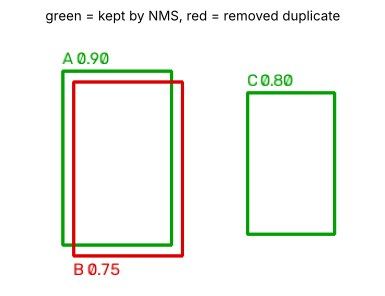

In [14]:
# Three predicted boxes (x1, y1, x2, y2): A and B cover the same object, C is another object
boxes = np.array([[50, 40, 150, 200], [60, 50, 160, 210], [220, 60, 300, 190]], np.float32)
# The confidence of each box (A 0.90, B 0.75, C 0.80)
scores = np.array([0.90, 0.75, 0.80])
# IoU of every box with every other box (a 3 x 3 table)
print("IoU matrix:\n", box_iou(boxes, boxes))
# Non-maximum suppression with an IoU threshold of 0.55
keep = nms(boxes, scores, iou_thr=0.55)
# Which boxes survive
print("NMS keeps boxes:", keep)

# A white canvas to draw on
canvas = np.full((240, 340, 3), 255, np.uint8)
# Draw every box with its name and score
for i, (b, s) in enumerate(zip(boxes.astype(int), scores)):
    # Green if NMS kept the box, red if NMS removed it
    color = (0, 160, 0) if i in keep else (220, 0, 0)
    # Draw the rectangle
    cv2.rectangle(canvas, tuple(b[:2]), tuple(b[2:]), color, 2)
    # Label position: above the box (below it for box B, so the labels do not overlap)
    y_text = b[3] + 18 if i == 1 else b[1] - 6
    # Write the box name and its score
    cv2.putText(canvas, f"{'ABC'[i]} {s:.2f}", (b[0], y_text), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
# Show the drawing
show(canvas, "green = kept by NMS, red = removed duplicate", width=6)

**👇 What the code below does**

Runs the detector on our robot's camera frame (confidence ≥ 0.25), prints
every box (class, confidence, pixel coordinates), draws the boxes, and
measures the average speed over 10 runs.

package   conf 0.87   box (332, 127) – (362, 178)
person    conf 0.85   box (275, 79) – (308, 191)



Detector speed on this CPU: 24 ms per frame (≈ 41 frames per second)


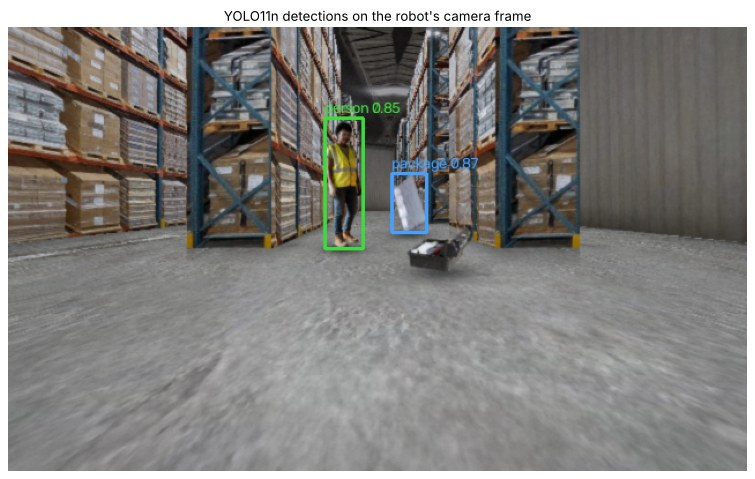

In [15]:
# Run the detector; every row of the result is one box: x1, y1, x2, y2, confidence, class
raw = detector(frame.rgb, conf=0.25)
# Go through the boxes
for x1, y1, x2, y2, conf, cls in raw:
    # Print the class, the confidence and the box corners
    print(f"{CLASS_NAMES[int(cls)]:9s} conf {conf:.2f}   box ({x1:.0f}, {y1:.0f}) – ({x2:.0f}, {y2:.0f})")

# Start a stopwatch
t0 = time.perf_counter()
# Run the detector 10 times on the same frame
for _ in range(10):
    # One detection
    detector(frame.rgb)
# Average time of one run, in milliseconds
ms = (time.perf_counter() - t0) / 10 * 1000
# Print the speed in milliseconds and in frames per second
print(f"\nDetector speed on this CPU: {ms:.0f} ms per frame (≈ {1000 / ms:.0f} frames per second)")

# A copy of the frame to draw on
vis = frame.rgb.copy()
# One colour per class: person green, forklift yellow, package blue
colors = {0: (60, 220, 60), 1: (255, 190, 30), 2: (70, 160, 255)}
# Draw every box
for x1, y1, x2, y2, conf, cls in raw:
    # The rectangle, in the colour of its class
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), colors[int(cls)], 2)
    # The class name and the confidence above the box
    cv2.putText(vis, f"{CLASS_NAMES[int(cls)]} {conf:.2f}", (int(x1), int(y1) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, colors[int(cls)], 1, cv2.LINE_AA)
# Show the result
show(vis, "YOLO11n detections on the robot's camera frame")

🔎 **What to notice:** the worker and the pallet are found with high
confidence. The **fallen tool case gets no box at all**: the detector has
no class for it. (After only 2 epochs of robot-view training the detector
even put a weak, wrong "package 0.32" box on it; the extra training removed
that false alarm.) Being blind to unknown objects is the most important
weakness of a detector-only robot, and the reason we also process the depth
image (section 7).

❓ **Ask the class:** *Could we just add a class "unknown object" to the
detector?* (Hint: how many kinds of objects can fall into an aisle? You
cannot collect training photos of every possible thing.)

**👇 What the code below does**

Runs the same detector on five **real photos** (warehouses, a construction
site, parcel conveyors) to show that it works on real images too, not only
in the simulation.

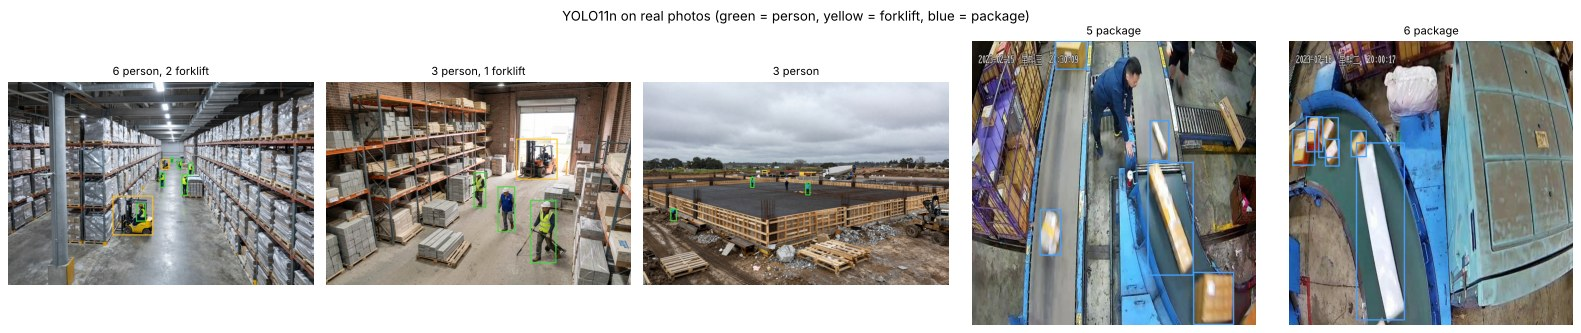

In [16]:
# One row of 5 plot areas
fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
# Go through the five example photos (numbered 1 to 5)
for i, ax in enumerate(axes, start=1):
    # Read photo number i (BGR → RGB); .copy() so we are allowed to draw on it
    img = cv2.imread(f"assets/examples/example_{i}.jpg")[:, :, ::-1].copy()
    # Detect objects with a confidence of at least 0.35
    dets = detector(img, conf=0.35)
    # A line thickness that suits the size of this photo
    thick = max(2, img.shape[1] // 300)
    # Draw every detected box
    for x1, y1, x2, y2, conf, cls in dets:
        # The rectangle, in the colour of its class
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), colors[int(cls)], thick)
    # The names of the detected classes
    found = [CLASS_NAMES[int(c)] for c in dets[:, 5]]
    # Show the photo
    ax.imshow(img)
    # Hide the axes
    ax.axis("off")
    # Title: how many objects of each class were found
    ax.set_title(", ".join(f"{found.count(c)} {c}" for c in CLASS_NAMES if c in found), fontsize=10)
# A title for the whole row
plt.suptitle("YOLO11n on real photos (green = person, yellow = forklift, blue = package)")
# Remove extra white space
plt.tight_layout()
# Display the figure
display_fig(fig)

🔎 **What to notice:** forklifts, workers in safety vests and parcels are
found in real photos. Look closely and you will also find **misses** (for
example a worker bending over a conveyor). No detector is perfect. That is
why the robot does not rely on the detector alone.

### How accurate is the detector? (test set of real photos)

🧠 **Concept: precision, recall, mAP**

* **Precision** = of everything the detector reported, how much was right?
  $\;P = \frac{TP}{TP + FP}$
* **Recall** = of all real objects, how many did it find?
  $\;R = \frac{TP}{TP + FN}$
* **AP@50** = area under the precision–recall curve (detections count as
  correct at IoU ≥ 0.5). **mAP@50** = the mean over the classes.

These results were measured on **189 real test photos** that were never used
for training.

**👇 What the code below does**

Reads the saved test-set results (`results/metrics/yolo_eval.json`), prints
the overall numbers, and draws a bar chart of AP@50 per class **before**
(COCO model without fine-tuning) and **after** fine-tuning on warehouse photos.

Test images: 189
mAP@50 87.7%   mAP@50-95 67.4%   precision 88.1%   recall 84.0%


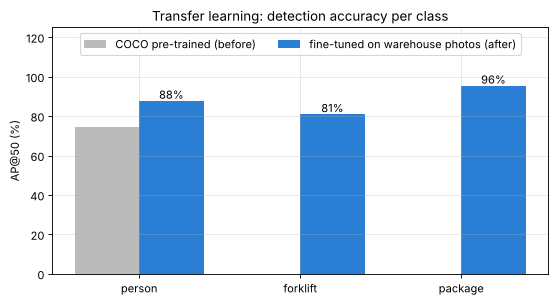

In [17]:
# Load the saved test-set results of the detector
yolo = json.load(open("results/metrics/yolo_eval.json"))
# The results of the fine-tuned model
ft = yolo["fine_tuned"]
# Number of test photos
print(f"Test images: {yolo['test_images']}")
# The overall scores, in percent
print(f"mAP@50 {100 * ft['mAP50']:.1f}%   mAP@50-95 {100 * ft['mAP50_95']:.1f}%   precision {100 * ft['precision']:.1f}%   recall {100 * ft['recall']:.1f}%")

# AP@50 per class, before and after fine-tuning
ba = yolo["before_vs_after_AP50"]
# The class names
cls = list(ba)
# AP@50 (%) of the COCO model, before fine-tuning
before = [100 * ba[c]["coco_pretrained"] for c in cls]
# AP@50 (%) after fine-tuning on warehouse photos
after = [100 * ba[c]["fine_tuned"] for c in cls]
# One position on the x-axis per class
x = np.arange(len(cls))
# A new chart
plt.figure(figsize=(8, 4))
# Grey bars: before fine-tuning
plt.bar(x - 0.2, before, 0.4, label="COCO pre-trained (before)", color="#bbb")
# Blue bars: after fine-tuning
plt.bar(x + 0.2, after, 0.4, label="fine-tuned on warehouse photos (after)", color="#2a7fd4")
# Go through the classes to label the blue bars
for i in range(len(cls)):
    # Write the value just above the blue bar
    plt.text(x[i] + 0.2, after[i] + 1, f"{after[i]:.0f}%", ha="center")
# Class names under the bars
plt.xticks(x, cls)
# Label of the y-axis
plt.ylabel("AP@50 (%)")
# Leave room above the bars for the legend
plt.ylim(0, 125)
# Chart title
plt.title("Transfer learning: detection accuracy per class")
# Legend at the top
plt.legend(loc="upper center", ncol=2)
# Show the chart
plt.show()

🔎 **What to notice:** before fine-tuning the model could not find forklifts
or parcels at all (COCO has no such classes). After fine-tuning on only
1,699 photos it reaches 81–96 % AP@50. This is the power of **transfer
learning**: the network already knows edges, shapes and textures, and only
has to learn the new classes.

**👇 What the code below does**

Shows two saved evaluation plots of the detector on the real test photos:
the **confusion matrix** (which class is confused with which) and the
**precision–recall curve**.

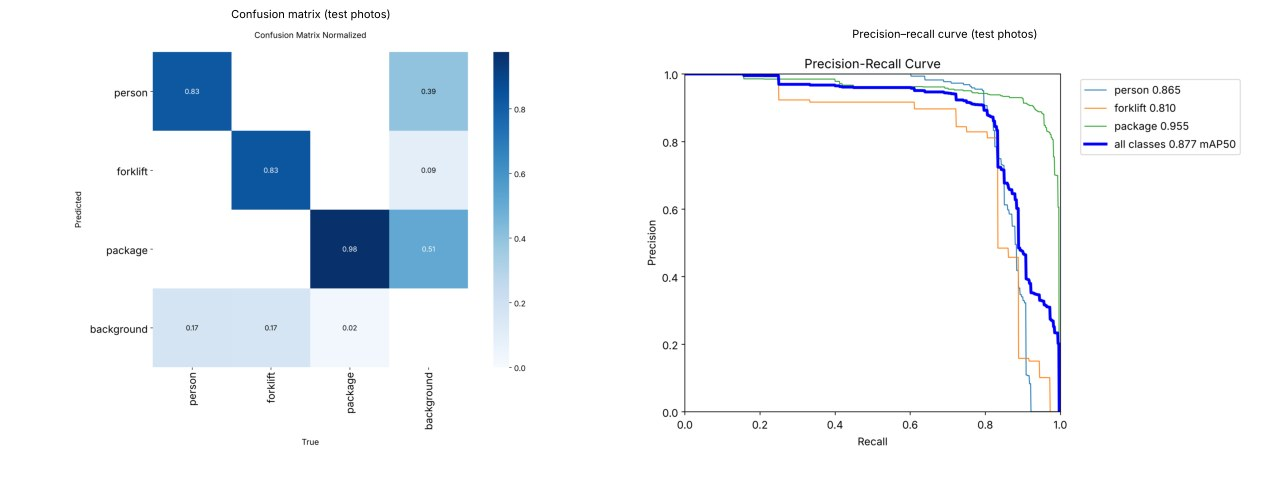

In [18]:
# Read the saved confusion-matrix picture
cm = plt.imread("results/graphs/yolo_confusion_matrix_test.png")
# Read the saved precision–recall curve picture
pr = plt.imread("results/graphs/yolo_pr_curve_test.png")
# Show both side by side
show_row([cm, pr], ["Confusion matrix (test photos)", "Precision–recall curve (test photos)"], width=16)

### Training more: robot-view fine-tuning, epoch 2 → epoch 8

🧠 **Concept: closing the domain gap**

People take photos from eye level. Our robot's camera hangs 0.6 m above the
floor, looking down a rack aisle. That is a different *domain*, and a
detector trained only on normal photos loses accuracy there. So we
fine-tuned it on **robot-view frames** built from cut-outs of *training*
photos ("cut, paste and learn"), mixed with the real photos so it does not
forget them.

The first 2 epochs were trained earlier, but only the exported ONNX file
survived; the PyTorch checkpoint was lost. We rebuilt a trainable model from
the ONNX file and **continued training for 6 more epochs (3 → 8)**, then
tested on data the detector never saw:

* 600 robot-view frames with objects from *val/test* photos, including a
  warehouse look never used in training;
* 189 real test photos;
* the robot **driving** 30 new warehouses (6,972 camera frames).

🧮 **The math: why ONNX weights cannot be trained directly**

During training every convolution is followed by **batch normalisation**
(BN). For export, the two are **fused** into one convolution:

$$W' = \frac{\gamma}{\sqrt{\sigma^2+\epsilon}}\,W, \qquad
b' = \beta + \frac{\gamma\,(b-\mu)}{\sqrt{\sigma^2+\epsilon}}$$

The ONNX file only keeps $W'$ and $b'$. To train again we **split them
back**: the convolution gets $W'$, and BN gets $\mu$ and $\sigma^2$ measured
on training images, with $\gamma = \sqrt{\sigma^2+\epsilon}$ and
$\beta = \mu + b'$. Then $\text{BN}(W'x) = W'x + b'$ exactly. The rebuilt
model reproduced the ONNX outputs to within 0.0006 pixels.

**👇 What the code below does**

1. Loads the saved results of the continued training
   (`results/metrics/detector_finetune.json`).
2. Prints a table: the original detector, epoch 2 and epoch 8 on the
   held-out robot-view frames and on the real test photos.
3. Prints how epoch 2 and epoch 8 did with the robot **driving**.
4. Shows the chart: validation curve per epoch, held-out tests, driving test.

detector                        robot-view mAP@50  precision  recall  real photos mAP@50
original (real photos only)                 58.0%      75.5%   46.4%               87.7%
robot-view, epoch 2                         91.9%      94.9%   82.2%               79.3%
robot-view, epoch 8                         95.7%      97.4%   91.9%               85.2%
robot driving, epoch2: precision 72.2%, recall 91.1%, false alarms 1637, missed 414
robot driving, epoch8: precision 94.8%, recall 99.0%, false alarms 255, missed 49


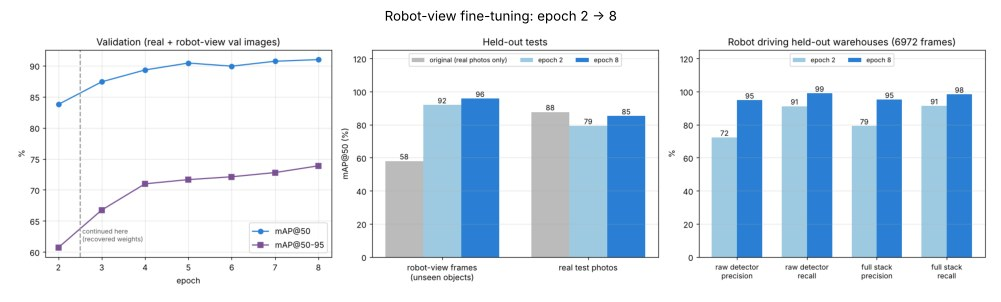

In [19]:
# Load the saved results of the continued (robot-view) training
tune = json.load(open("results/metrics/detector_finetune.json"))
# The held-out test results of the three detectors
held = tune["heldout_tests"]["results"]
# Readable names for the three detectors
det_names = {"original": "original (real photos only)", "epoch2": "robot-view, epoch 2", "epoch8": "robot-view, epoch 8"}
# The table header
print(f"{'detector':30s} {'robot-view mAP@50':>18s} {'precision':>10s} {'recall':>7s} {'real photos mAP@50':>19s}")
# One table row per detector
for key, name in det_names.items():
    # Its scores on the robot-view frames with unseen objects
    sim = held[key]["sim_heldout"]
    # Print the robot-view scores and the real-photo score
    print(f"{name:30s} {100 * sim['mAP50']:17.1f}% {100 * sim['P']:9.1f}% {100 * sim['R']:6.1f}% {100 * held[key]['real_test']['mAP50']:18.1f}%")
# The results with the robot driving 30 held-out warehouses
in_sim = tune["in_simulation"]["results"]
# Compare epoch 2 and epoch 8
for key in ("epoch2", "epoch8"):
    # The raw detector's scores on the driving video
    scores = in_sim[key]["driving_video"]["raw_detector"]
    # Print precision, recall, false alarms and missed objects
    print(f"robot driving, {key}: precision {100 * scores['precision']:.1f}%, recall {100 * scores['recall']:.1f}%, false alarms {scores['fp']}, missed {scores['fn']}")
# Show the chart: validation per epoch, held-out tests, driving test
show(plt.imread("results/graphs/yolo_robotview_finetune.png"), "Robot-view fine-tuning: epoch 2 → 8", width=16)

🔎 **What to notice**

* More training helped everywhere it matters for the robot: on unseen
  objects in robot-view frames, mAP@50 went from 92 % to **96 %** and recall
  from 82 % to **92 %**.
* With the robot driving, false alarms dropped from 1,637 to **255** and
  missed objects from 414 to **49**.
* On real photos the robot-view model (85 %) is still a little below the
  original model (88 %). That is why the "Real image detection" tab keeps
  the original model. **Pick the model for the job, measured on held-out
  data.**

❓ **Ask the class:** *Why do we test on objects from val/test photos and on a
warehouse look that was never used for training?*

✅ **Recap:** YOLO11n finds people, forklifts and parcels in one pass
(letterbox → network → decode → NMS). Fine-tuning for the robot's viewpoint
made it much more accurate in the robot's camera. It is accurate on the
classes it knows, but **blind to everything else**.

---
# 7. Depth-image processing: finding what is not on the map

🎯 **Learning goals:** use classic **image processing** on the depth image
to find *any* obstacle, even one nobody has ever labelled.

🧠 **Concept: background subtraction with a map**

In video surveillance a fixed camera learns what the empty scene looks like;
anything different is **foreground** (a person walking in). Our camera moves,
but the robot knows **its map and its position**. So for every frame it can
compute the **expected depth image of the empty warehouse** (only racks,
walls, floor). Then:

> **foreground = pixels that are clearly *closer* than the map says.**

Something is standing there that is not on the map, so it is an obstacle.

**👇 What the code below does**

* Ray-casts the known map from the robot's pose into an **expected depth
  image** (`static_depth`): what the camera would see if the aisle were empty.
* Shows the measured depth, the expected depth, and their difference
  (blue = measured is closer than expected).

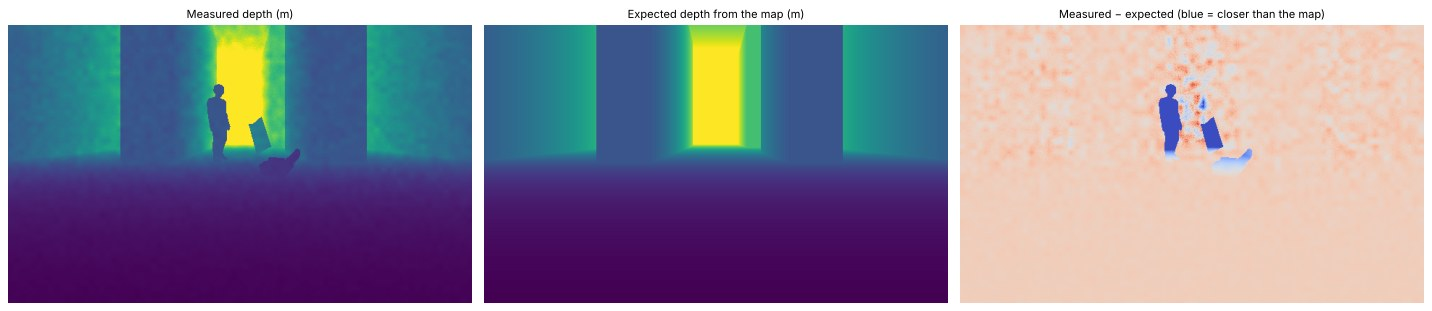

In [20]:
# The scene's camera and its perception stack
cam, vision = scene.camera, scene.vision
# The measured depth image (metres)
depth = frame.depth
# The expected depth image of the EMPTY warehouse, ray-cast from the map
z_map = cam.static_depth(scene)
# Measured minus expected: negative where something is closer than the map says
diff = depth - z_map

# Show measured, expected and the difference (values clipped so the colours are clear)
show_row([np.clip(depth, 0, 10), np.clip(z_map, 0, 10), np.clip(diff, -3, 3)], ["Measured depth (m)", "Expected depth from the map (m)", "Measured − expected (blue = closer than the map)"], cmaps=["viridis", "viridis", "coolwarm"], width=18)

🧮 **The math: the foreground test**

A pixel $(u, v)$ with measured depth $z$ is **foreground** if two things
hold:

1. **It is clearly closer than the map**

$$z < z_{\text{map}}\,(1 - \rho) - 0.10\ \text{m},\qquad
\rho = \max(0.07,\; 2.6\,\sigma)$$

   where $\sigma$ is the **noise level of this frame**, measured robustly on
   the floor just in front of the robot with the *median absolute deviation*
   (MAD). Noisy sensor → stricter threshold. This is an **adaptive
   threshold**.

2. **Its height above the floor is between 0.15 m and 1.7 m.** From the
   pinhole model: $\;\text{height} = h_{cam} - \dfrac{(v - c_y)\,z}{f}$.
   This removes floor pixels (small noise would otherwise look like
   obstacles) and things above the robot.

Then a **morphological opening** (erosion followed by dilation with a 3 × 3
kernel) removes isolated noisy pixels while keeping real blobs.

**👇 What the code below does**

Repeats the perception stack's foreground computation **step by step**, so
you can see each image-processing operation:

1. height of every pixel above the floor → the "robot height band";
2. noise level σ of this frame (MAD on the floor) → adaptive threshold;
3. raw foreground mask;
4. foreground after morphological opening.

depth noise in this frame σ = 3.4%  →  threshold ρ = 8.8%
foreground pixels: raw 3684, after opening 3603


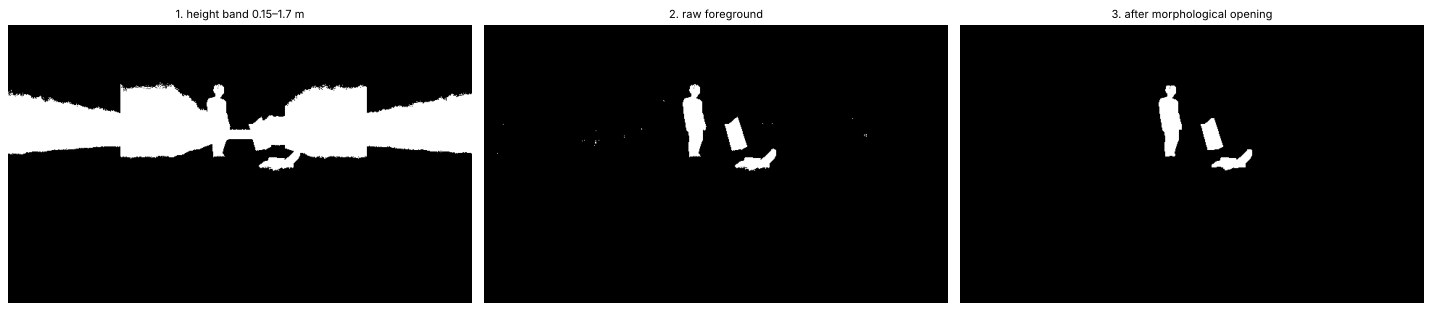

In [21]:
# Height of every pixel above the floor: h = h_cam − (v − cy) · z / f
height = cam.cam_h - cam.dy[:, None] * depth / cam.f
# Keep only pixels between 0.15 m and 1.7 m high (the robot's height band)
band = (height > 0.15) & (height < 1.7)

# The noise level of this frame, measured robustly on the floor (median absolute deviation)
sigma = vision._noise_level(depth, z_map)
# Adaptive threshold: at least 7 %, more when the sensor is noisy
rho = max(0.07, 2.6 * sigma)
# Print the noise level and the threshold in percent
print(f"depth noise in this frame σ = {100 * sigma:.1f}%  →  threshold ρ = {100 * rho:.1f}%")

# Raw foreground: inside the height band AND clearly closer than the map
fg_raw = band & (depth < z_map * (1 - rho) - 0.10)
# A 3 x 3 square, used by the morphology operation
kernel = np.ones((3, 3), np.uint8)
# Morphological opening (erosion, then dilation) removes isolated noisy pixels
fg = cv2.morphologyEx(fg_raw.astype(np.uint8), cv2.MORPH_OPEN, kernel).astype(bool)
# How many foreground pixels there are before and after the opening
print(f"foreground pixels: raw {fg_raw.sum()}, after opening {fg.sum()}")

# Show the three masks (white = True)
show_row([band, fg_raw, fg], ["1. height band 0.15–1.7 m", "2. raw foreground", "3. after morphological opening"], cmaps=["gray", "gray", "gray"], width=18)

🔎 **What to notice:** racks, walls and floor disappear (they are on the
map). What remains are three blobs: the worker, the pallet **and the
unknown object**, the one the detector could not see. Depth processing
finds obstacles **by geometry, without knowing what they are**.

🧠 **Concept: from a depth image to a "laser scan"**

The policy does not read 245,760 depth pixels. Like a real AMR (the ROS
package `depthimage_to_laserscan` does the same), we reduce the image to
**21 rays** spread over the 120° field of view. For each ray we take the
**nearest return** in its image column window, using the 10th percentile
instead of the minimum so that one noisy pixel cannot create a phantom
obstacle.

**👇 What the code below does**

Runs the complete perception stack once on the frame (`vision.process`) and
plots, for all 21 rays, the distance measured from the depth image next to
the true distance from the simulator, as a top-down "radar" plot.

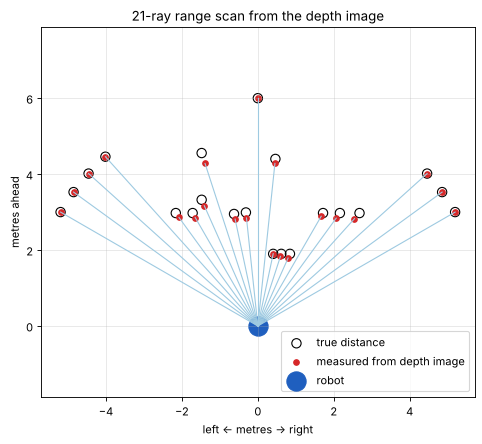

median ray error: 4.5%


In [22]:
# Start the perception stack fresh (forget old tracks)
vision.reset()
# Process the same frame 3 times so that the tracks get confirmed
for _ in range(3):
    # Full perception: depth processing + detector + fusion + tracking
    result = vision.process(scene, frame)

# The true distance along each of the 21 rays (from the simulator, for comparison)
true_d, _ = scene.cast(scene.ray_angles)
# The 21 ray angles (radians; left is positive)
ang = scene.ray_angles
# A new, almost square figure
plt.figure(figsize=(7, 6))
# Go through the rays
for a, d in zip(ang, result.depth):
    # Draw the ray as a line from the robot to the measured distance (x = right, y = ahead)
    plt.plot([0, -d * math.sin(a)], [0, d * math.cos(a)], color="#9ecae1", lw=1)
# Black circles: the true distances
plt.scatter(-true_d * np.sin(ang), true_d * np.cos(ang), s=70, facecolors="none", edgecolors="k", label="true distance")
# Red dots: the distances measured from the depth image
plt.scatter(-result.depth * np.sin(ang), result.depth * np.cos(ang), s=25, color="#d62728", label="measured from depth image")
# The robot, at the origin
plt.scatter([0], [0], s=300, color="#1f5fbf", label="robot")
# Same scale on both axes, so metres look like metres
plt.axis("equal")
# Label of the x-axis
plt.xlabel("left ← metres → right")
# Label of the y-axis
plt.ylabel("metres ahead")
# Chart title
plt.title("21-ray range scan from the depth image")
# Legend in the lower right corner
plt.legend(loc="lower right")
# Show the plot
plt.show()
# The rays that hit something closer than 5.9 m
hit = true_d < 5.9
# Absolute error of those rays
err = np.abs(result.depth - true_d)[hit]
# Print the median relative error in percent
print(f"median ray error: {100 * np.median(err / true_d[hit]):.1f}%")

✅ **Recap:** with the **map as background**, a simple pipeline (expected
depth → adaptive threshold → height band → morphological opening →
percentile range scan) finds every obstacle in the aisle, **including
unknown ones**.

---
# 8. Sensor fusion: from pixels to metres

🎯 **Learning goals:** combine the **detector** (what) and the **depth
image** (where), and reject wrong detections with physical checks.

🧠 **Concept: two independent distance measurements per box**

For every detector box we compute the distance **twice**:

1. **From depth:** the 25th percentile of the foreground depth pixels inside
   the box.
2. **From geometry:** where the bottom of the box touches the floor
   ($z = f\,h / (v_{bottom} - c_y)$, section 5).

If both agree, we trust the depth. If they disagree (for example the shiny
stretch wrap makes the depth sensor "see through" the film), the **nearer**
value wins. When in doubt, assume the obstacle is close: that is the safe
side.

**Gates** (sanity checks) remove impossible detections:

* **"flat on the map" gate:** a box with almost no foreground inside (for
  example a *picture* of a parcel printed on a rack) is not an obstacle in
  the aisle;
* **size gate:** a "person" 4 m tall, or 20 cm tall but not cut off by the
  image border, is rejected.

**👇 What the code below does**

For each detector box (confidence ≥ 0.25):

* computes the two distances (from depth pixels and from the floor contact)
  with the same function the perception stack uses (`_box_range`);
* finds the real object under the box (best IoU with the simulator's ground
  truth) and prints what it **really** is and its true distance.

In [23]:
# Image height in pixels
H_img = depth.shape[0]
# All true boxes from the simulator, as one array
gt_boxes = np.array([g["bbox"] for g in frame.gt], np.float32)
# A small helper that prints a distance, or a dash when there is none
fmt = lambda v: f"{v:6.2f} m" if v is not None else "     – "
# The table header
print(f"{'detected as':12s} {'conf':>5s} {'depth':>8s} {'floor':>8s}   {'really is':10s} {'true':>7s}")
# Go through the detector boxes
for x1, y1, x2, y2, conf, cls in result.raw:
    # Very weak boxes ...
    if conf < 0.25:
        # ... are skipped
        continue
    # Distance from the depth pixels (z_depth) and from the floor contact (z_floor)
    z_depth, z_floor, frac, cut = vision._box_range((x1, y1, x2, y2), depth, fg, cam.f, cam.cy, cam.cam_h, H_img)
    # The true object with the largest overlap (IoU) with this box
    j = int(np.argmax(box_iou(np.array([[x1, y1, x2, y2]]), gt_boxes)[0]))
    # Its ground-truth record
    truth = frame.gt[j]
    # One table row: the detection, both distances, what it really is, and its true distance
    print(f"{CLASS_NAMES[int(cls)]:12s} {conf:5.2f} {fmt(z_depth)} {fmt(z_floor)}   {truth['class_name']:10s} {truth['z']:5.2f} m")

detected as   conf    depth    floor   really is     true
package       0.87   4.31 m   4.54 m   package     4.40 m
person        0.85   2.89 m   2.94 m   person      2.92 m


🔎 **What to notice**

* The two methods are independent (one uses depth pixels, the other only
  the colour image plus geometry), yet they agree within a few centimetres
  of the truth. Two independent measurements of the same thing is a classic
  reliability trick in robotics (*redundancy*).
* Only the worker and the pallet have boxes. The **unknown tool case** has
  none, so neither method can measure it here. It is found in the next cell,
  by depth alone.

**👇 What the code below does**

Prints what the full perception stack reports for this frame:

* **tracked objects**: class, confidence, distance, bearing, track id;
* **unknown obstacles**: foreground blobs not explained by any detection;
* boxes **rejected** by the gates;
* how long each stage took.

In [24]:
# Every tracked object the perception stack reports
for o in result.objects:
    # Its class, confidence, distance, direction and track number
    print(f"object  {o['name']:9s} conf {o['conf']:.2f}  range {o['range']:.2f} m  bearing {math.degrees(o['bearing']):+5.1f}°  track #{o['tid']}")
# Every unknown obstacle (found by depth only)
for u in result.unknown:
    # Its distance and the size of its blob
    print(f"UNKNOWN obstacle (depth only) at {u['z']:.2f} m, {u['area']} px blob")
# Boxes removed by the gates (with the reason)
print("rejected boxes:", result.rejected or "none")
# Time spent in each stage, in milliseconds
print("time per stage (ms):", {k: round(v, 1) for k, v in result.ms.items()})

object  package   conf 0.87  range 4.35 m  bearing  -8.5°  track #1
object  person    conf 0.85  range 2.92 m  bearing  +8.7°  track #2
UNKNOWN obstacle (depth only) at 1.83 m, 185 px blob
rejected boxes: none
time per stage (ms): {'depth': 3.7, 'detector': 17.7, 'fusion': 8.9}


**👇 What the code below does**

Draws the final perception output on the camera image (`draw_overlay`):
coloured boxes for tracked objects with their distance, and a **magenta**
box for the unknown obstacle found by depth only.

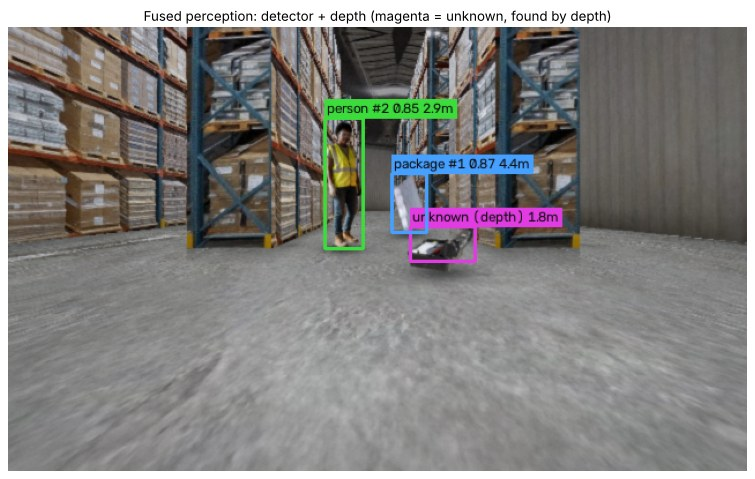

In [25]:
# Draw the perception result on the camera image and show it
show(draw_overlay(frame.rgb, result), "Fused perception: detector + depth (magenta = unknown, found by depth)")

🔎 **What to notice:** the unknown object now **has a box and a distance**,
even though the detector could not recognise it: the depth branch reports it
as **unknown**. Even if the detector makes a weak guess (below 0.40, the
confidence needed to **start** a new track, the ByteTrack rule from section
9), the stack does not trust that label. Either way, the robot avoids it.

❓ **Ask the class:** *Why does the robot treat an unknown obstacle like a
pallet and not like a person?* (It cannot know it is a person, but it still
avoids it. The extra safety margin for people needs the detector.)

### Per-ray labels: the fused result as the robot uses it

Every one of the 21 rays now carries a **distance** and a **label**:
`person`, `forklift`, `pallet` (from the detector), `rack` / `wall` (rays that
agree with the map) or `unknown` (depth only).

**👇 What the code below does**

Plots the 21 fused rays from above, coloured by their label, using the
values the environment stores after perception (`fused_rays`,
`ray_labels`).

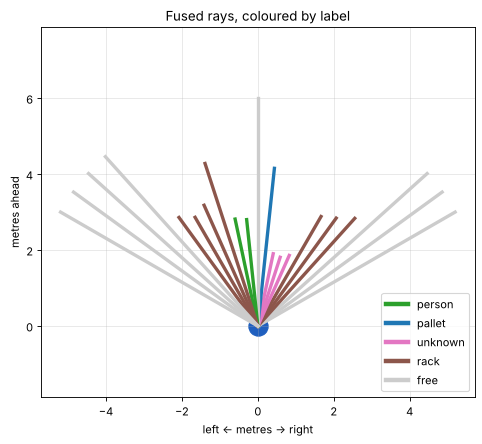

In [26]:
# One colour per label
label_color = {PERSON: "#2ca02c", FORKLIFT: "#ffbf00", PALLET: "#1f77b4", BOX: "#e377c2", RACK: "#8c564b", WALL: "#7f7f7f", -1: "#cccccc"}
# A new figure
plt.figure(figsize=(7, 6))
# Go through the fused rays with their labels
for a, d, lab in zip(scene.ray_angles, scene.fused_rays, scene.ray_labels):
    # Draw the ray from the robot to its fused distance, in the colour of its label
    plt.plot([0, -d * math.sin(a)], [0, d * math.cos(a)], color=label_color[int(lab)], lw=3)
# Build the legend: go through all labels
for lab, col in label_color.items():
    # Only labels that appear in this scene
    if lab in scene.ray_labels:
        # An empty line that only adds an entry to the legend
        plt.plot([], [], color=col, lw=4, label=CATEGORY_NAMES[lab])
# The robot
plt.scatter([0], [0], s=300, color="#1f5fbf")
# Same scale on both axes
plt.axis("equal")
# The legend
plt.legend(loc="lower right")
# Chart title
plt.title("Fused rays, coloured by label")
# Label of the x-axis
plt.xlabel("left ← metres → right")
# Label of the y-axis
plt.ylabel("metres ahead")
# Show the plot
plt.show()

✅ **Recap:** fusion gives every obstacle a **class** (if the detector knows
it) and a **reliable distance** (depth + geometry, nearer wins). Gates throw
away impossible boxes. Depth alone catches the unknown objects.

---
# 9. Video processing: tracking objects over time

🎯 **Learning goals:** see why single frames are not enough, and how a
**Kalman filter** turns noisy detections into smooth tracks with a
**velocity**.

🧠 **Concept**

A detector looks at **one frame at a time**. In a video it:

* sometimes **misses** an object for a frame (blur, occlusion);
* produces boxes that **jitter** from frame to frame;
* cannot tell **how fast** something moves.

**Tracking** links detections across frames. Because our camera is on a
robot that drives and turns, tracking in the image would lose every object
in a turn. So we project each detection **onto the floor** (world
coordinates, using the robot's pose) and track it there.

🧮 **The math: constant-velocity Kalman filter**

State of a track: $\mathbf{x} = [x, y, v_x, v_y]^\top$ (position and velocity
on the floor). Every frame ($\Delta t = 0.2$ s):

**Predict** (move the track forward with its velocity):
$$\hat{\mathbf{x}} = F\mathbf{x}, \qquad \hat P = F P F^\top + Q,
\qquad F = \begin{bmatrix}1&0&\Delta t&0\\0&1&0&\Delta t\\0&0&1&0\\0&0&0&1\end{bmatrix}$$

**Update** (correct it with the new measurement $\mathbf{z} = [x, y]$):
$$K = \hat P H^\top (H \hat P H^\top + R)^{-1},\qquad
\mathbf{x} = \hat{\mathbf{x}} + K(\mathbf{z} - H\hat{\mathbf{x}}),\qquad
P = (I - KH)\hat P$$

* $P$ = how uncertain the track is, $Q$ = how much the object can
  accelerate, $R$ = how noisy the measurement is.
* Our $R$ is built from the camera: the **bearing** (left/right) is
  accurate, the **range** (distance) is noisier and gets worse far away.
* The **Kalman gain** $K$ decides how much to trust the new measurement
  versus the prediction.

**Association** (which detection belongs to which track) works in two
stages, as in **ByteTrack**: confident detections are matched first, and weak
ones (confidence ≥ 0.15) may only *extend* an existing track, never start a
new one. A track is confirmed after 2 hits and survives up to 4 missed frames
(*coasting*).

**👇 What the code below does**

A toy experiment with the real tracker class (`GroundTracker`):

* a worker walks at **1.0 m/s** along x;
* each frame we give the tracker a **noisy** detection (±15 cm);
* in frames 8–10 the detector **misses** the worker completely.

Then we plot the true path, the noisy detections and the tracked position,
plus the estimated speed.

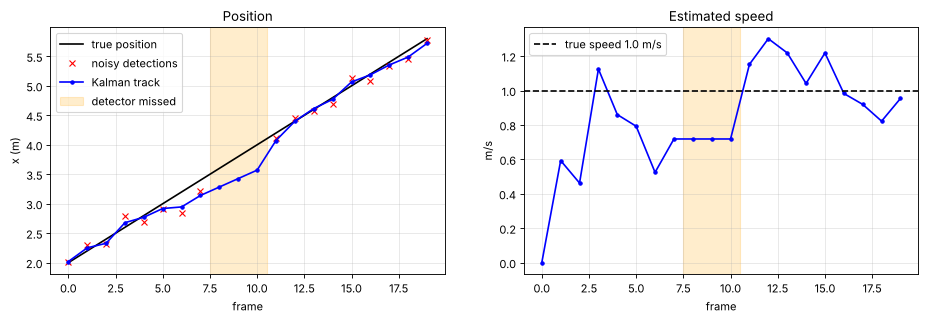

track id stayed the same: #1; final speed estimate 0.95 m/s


In [27]:
# Random numbers for the measurement noise (seed 0 = the same every time)
rng = np.random.default_rng(0)
# A new tracker; one frame lasts 0.2 s
tracker = GroundTracker(dt=0.2)
# Lists to record: true x, measured x, tracked x, and the estimated speed
true_x, meas_x, track_x, speed = [], [], [], []
# 20 frames
for k in range(20):
    # True position: walking at 1.0 m/s along x, starting at x = 2 m
    x_true, y_true = 2.0 + 1.0 * 0.2 * k, 1.0
    # The detections of this frame (stays empty when the detector misses)
    dets = []
    # In frames 8, 9 and 10 the detector misses the worker
    if k not in (8, 9, 10):
        # Noisy measured x (about ±15 cm)
        xm = x_true + rng.normal(0, 0.15)
        # Noisy measured y (about ±5 cm)
        ym = y_true + rng.normal(0, 0.05)
        # One person detection at the measured position
        dets = [Detection3D(xm, ym, math.hypot(xm, ym), math.atan2(ym, xm), cls=0, conf=0.8, box=(0, 0, 10, 20), half_width=0.3, height=1.7)]
        # Remember the measurement for the plot
        meas_x.append((k, xm))
    # One tracker step: predict, then update with this frame's detections
    tracks = tracker.step(dets, robot_theta=0.0)
    # Record the true position
    true_x.append(x_true)
    # Record the tracked position (NaN when there is no track yet)
    track_x.append(tracks[0].state[0] if tracks else np.nan)
    # Record the estimated speed
    speed.append(tracks[0].speed if tracks else np.nan)

# Two plots side by side
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
# Left plot: the true position
a1.plot(true_x, "k-", label="true position")
# Left plot: the noisy detections
a1.plot(*zip(*meas_x), "rx", label="noisy detections")
# Left plot: the Kalman track
a1.plot(track_x, "b.-", label="Kalman track")
# Left plot: shade the frames the detector missed
a1.axvspan(7.5, 10.5, color="orange", alpha=0.2, label="detector missed")
# Left plot: label of the x-axis
a1.set_xlabel("frame")
# Left plot: label of the y-axis
a1.set_ylabel("x (m)")
# Left plot: legend
a1.legend()
# Left plot: title
a1.set_title("Position")
# Right plot: the estimated speed
a2.plot(speed, "b.-")
# Right plot: the true speed as a dashed line
a2.axhline(1.0, color="k", ls="--", label="true speed 1.0 m/s")
# Right plot: shade the frames the detector missed
a2.axvspan(7.5, 10.5, color="orange", alpha=0.2)
# Right plot: label of the x-axis
a2.set_xlabel("frame")
# Right plot: label of the y-axis
a2.set_ylabel("m/s")
# Right plot: legend
a2.legend()
# Right plot: title
a2.set_title("Estimated speed")
# Show both plots
plt.show()
# The track kept one ID the whole time: print it and the final speed estimate
print(f"track id stayed the same: #{tracks[0].tid}; final speed estimate {tracks[0].speed:.2f} m/s")

🔎 **What to notice**

* The blue track is **smoother** than the red detections (noise is filtered).
* During the 3 missed frames the track **keeps going** (it *coasts* with its
  predicted velocity) and keeps the **same ID**.
* The speed estimate converges towards the true 1 m/s. The detector alone
  could never measure speed.

**👇 What the code below does**

Now the same tracker inside the real perception stack. We build the demo
scene again, but this time the worker **walks across the aisle** at
0.8 m/s while the robot waits. The robot's camera runs for 12 frames.
After each frame we print the worker's track: ID, distance, and the
estimated walking velocity compared with the true one.

frame  0: track #2  range 2.78 m  velocity (+0.00, +0.00) m/s   true (+0.00, -0.80)


frame  1: track #2  range 2.74 m  velocity (-0.03, -0.32) m/s   true (+0.00, -0.80)
frame  2: track #2  range 2.73 m  velocity (+0.06, -0.72) m/s   true (+0.00, -0.80)
frame  3: track #2  range 2.68 m  velocity (-0.05, -0.69) m/s   true (+0.00, -0.80)


frame  4: track #2  range 2.66 m  velocity (-0.04, -0.72) m/s   true (+0.00, -0.80)


frame  5: track #2  range 2.63 m  velocity (-0.07, -0.71) m/s   true (+0.00, -0.80)
frame  6: track #2  range 2.65 m  velocity (+0.01, -0.70) m/s   true (+0.00, -0.80)
frame  7: track #2  range 2.67 m  velocity (+0.03, -0.63) m/s   true (+0.00, -0.80)


frame  8: track #2  range 2.68 m  velocity (+0.01, -0.69) m/s   true (+0.00, -0.80)


frame  9: track #2  range 2.71 m  velocity (+0.01, -0.75) m/s   true (+0.00, -0.80)
frame 10: track #2  range 2.77 m  velocity (+0.05, -0.76) m/s   true (+0.00, -0.80)
frame 11: track #2  range 2.79 m  velocity (+0.01, -0.70) m/s   true (+0.00, -0.80)


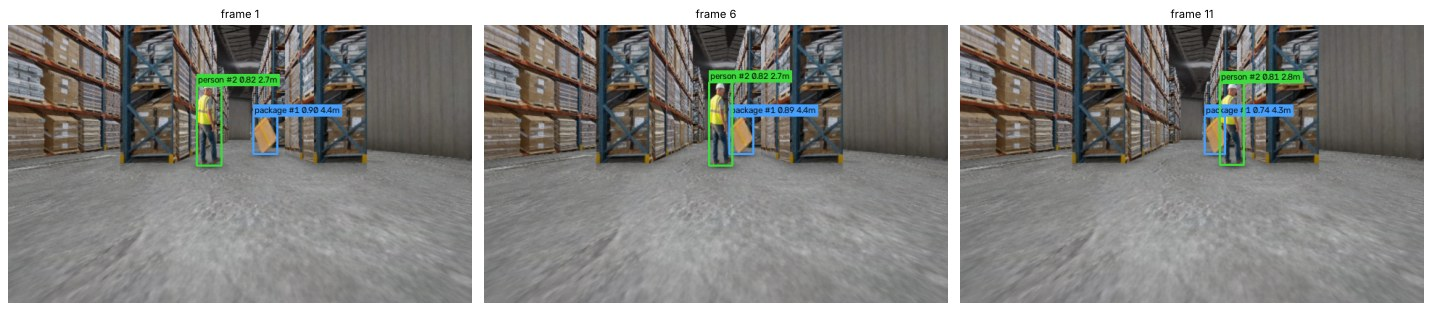

In [28]:
# A fresh demo scene (same warehouse, robot looking down the aisle)
walk = make_scene_env()
# The lower and upper edge (y coordinates) of the robot's aisle
lo, hi = walk.aisles[1]
# A worker 3 m ahead and 1 m to the left, walking across the aisle at 0.8 m/s
worker = Obstacle(PERSON, walk.x + 3.0, walk.y + 1.0, radius=0.28, uid=950, vy=-0.8, axis=1, bounds=(lo + 0.4, hi - 0.4))
# Add the walking worker to the moving obstacles
walk.dynamics.append(worker)
# A pallet further ahead, on the right
place(walk, PALLET, 5.0, -0.9, uid=951)

# Pictures to show at the end
snapshots = []
# 12 frames
for k in range(12):
    # The robot stands still (STOP) while the world moves on for 0.2 s
    walk.step(STOP)
    # Look at everything the perception reports in this frame
    for o in walk.vision_result.objects:
        # We only care about the person
        if o["name"] == "person":
            # Print the track ID, distance, estimated velocity and the true velocity
            print(f"frame {k:2d}: track #{o['tid']}  range {o['range']:.2f} m  velocity ({o['vel'][0]:+.2f}, {o['vel'][1]:+.2f}) m/s   true ({worker.vx:+.2f}, {worker.vy:+.2f})")
    # For frames 1, 6 and 11 ...
    if k in (1, 6, 11):
        # ... keep the camera image with the perception boxes drawn on it
        snapshots.append(draw_overlay(walk.frame.rgb, walk.vision_result))
# Show the three pictures
show_row(snapshots, ["frame 1", "frame 6", "frame 11"], width=18)

🔎 **What to notice:** the worker keeps **the same track ID** in every frame,
and the estimated velocity approaches the true walking velocity after a few
frames. The robot now knows not only **where** the worker is, but also
**where the worker is going**.

✅ **Recap:** tracking = **video processing**. It removes flicker, bridges
missed frames and measures velocity, which the policy uses as *closing speed*.

---
# 10. The obstacle map: what the robot's "brain" reads

🎯 **Learning goals:** understand the **state** of the reinforcement-learning
problem.

🧠 **Concept**

The policy does **not** read raw pixels. It reads a compact **obstacle map**
of 47 numbers, all scaled to $[-1, 1]$:

| Part | Size | Meaning |
|---|---|---|
| fused rays | 21 | distance along each ray |
| sector distances | 7 | the nearest distance in each of 7 sectors (left → right) |
| sector classes | 7 | is the nearest thing a person (1), a forklift (0.5) or other (0)? |
| closing speeds | 7 | how fast each sector's obstacle approaches |
| direction to path | 2 | sin and cos of the angle to the next waypoint |
| goal distance | 1 | |
| speed | 1 | the robot's own speed |
| uncertainty | 1 | how much the robot should doubt its depth readings |

**Why so compact?** It is the same whether it comes from the simulator or
from a real camera (*sim-to-real*): we can swap the perception without
retraining the policy. That is exactly what we did when we connected the
real-image camera.

**👇 What the code below does**

Takes the current observation of our demo scene and splits the 47 numbers
into their parts, printing each part, so you can read the obstacle map like
the policy does.

In [29]:
# The 47-number observation of the demo scene
obs = scene._observation()
# Split it into its named parts (start:end positions in the vector)
parts = {"fused rays (21)": obs[0:21], "sector distances (7)": obs[21:28], "sector classes (7)": obs[28:35], "closing speeds (7)": obs[35:42], "path sin, cos, goal dist, speed, uncertainty": obs[42:47]}
# Go through the parts
for name, values in parts.items():
    # Print the name of the part and its numbers
    print(f"{name:46s} {values}")
# Check the total length, and that every value lies between -1 and 1
print("\ntotal:", obs.shape[0], "numbers, all between -1 and 1:", bool(np.all(np.abs(obs) <= 1)))

fused rays (21)                                [ 1.    1.    1.    0.27  0.17  0.11 -0.32 -0.37 -0.35  0.39  1.   -0.06
 -0.04  0.5   0.16  0.1   0.18  1.    1.    1.    1.  ]
sector distances (7)                           [ 1.    0.11 -0.37 -0.06 -0.04  0.1   1.  ]
sector classes (7)                             [-1. -1. -1.  1.  1. -1. -1.]
closing speeds (7)                             [0.   0.   0.   0.   0.03 0.03 0.  ]
path sin, cos, goal dist, speed, uncertainty   [ 0.09  1.    1.   -1.   -0.87]

total: 47 numbers, all between -1 and 1: True


🔎 **What to notice:** in the *sector classes* a value of **+1** marks the
sectors whose nearest obstacle is the **worker**. The policy has learned to
give people more room.

---
# 11. Decision making with reinforcement learning (PPO)

🎯 **Learning goals:** know the parts of the RL problem (state, action,
reward) and the idea of PPO.

🧠 **Concept: learning by trial and error**

| RL element | In our project |
|---|---|
| **Agent** | the robot's policy (a small neural network) |
| **State** $s$ | the 47-number obstacle map |
| **Action** $a$ | GO (1.5 m/s), SLOW (0.6 m/s), STOP, TURN_LEFT, TURN_RIGHT |
| **Reward** $r$ | + progress along the path, +10 at the goal, −10 for a collision, − near misses (bigger near people), − harsh braking, −0.01 per step |
| **Episode** | one drive from start to goal (max 450 steps = 90 s) |

The agent tries actions, receives rewards, and slowly changes its network so
that actions with high long-term reward become more likely.

🧮 **The math: PPO in one formula**

The policy $\pi_\theta(a \mid s)$ gives a probability for each action. PPO
maximises

$$L^{CLIP}(\theta) = \mathbb{E}_t\Big[\min\big(r_t(\theta)\,\hat A_t,\;
\text{clip}(r_t(\theta),\,1-\epsilon,\,1+\epsilon)\,\hat A_t\big)\Big],
\qquad r_t(\theta) = \frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}$$

* $\hat A_t$ (the **advantage**) says: was this action **better or worse
  than usual** in this state? (estimated with GAE, $\gamma = 0.99$,
  $\lambda = 0.95$)
* The **clip** ($\epsilon = 0.2$) stops the policy from changing too much in
  one update. That makes PPO stable and the reason it is so popular.

**Training:** Stable-Baselines3, 4 parallel environments, 1.2 million steps,
MLP with 2 hidden layers of 64 neurons (tanh). After training we exported the
weights to NumPy, so the robot needs no PyTorch.

⚠️ **A real lesson from this project: reward hacking**

In a first version the progress reward was measured on the **re-planned**
path. When the robot re-planned around an obstacle, the path got shorter and
the robot received "free" progress reward. The policy discovered this and
learned to **drive in circles to trigger re-planning**. We fixed it by
measuring progress on the **static map**, which never changes.

❓ **Ask the class:** *The robot did exactly what the reward said, so whose
fault was it?* (Designing rewards is hard: an RL agent optimises **what you
measure, not what you mean**.)

**👇 What the code below does**

Loads the trained PPO policy (NumPy file), prints the shape of each network
layer and the number of parameters, then asks the policy what it would do
in our demo scene and plots its **probability for each action**.

hidden layer 1:  47 → 64 neurons (tanh)
hidden layer 2:  64 → 64 neurons (tanh)
output layer  :  64 → 5 actions
total parameters: 7,557  (tiny, ≈ 0.2 ms per decision)


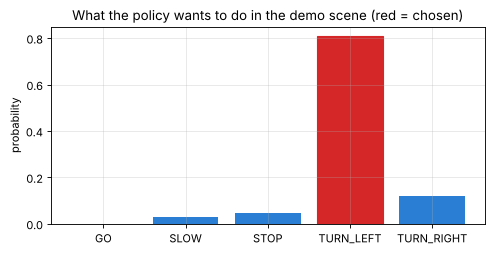

In [30]:
# Load the trained PPO policy (its weights are stored as a NumPy file)
policy = NumpyPolicy()
# Counter for the number of network parameters
n_params = 0
# Go through the hidden layers (weight matrix Wt and bias vector b)
for i, (Wt, b) in enumerate(policy.weights):
    # Print inputs → neurons of this layer, and its activation function
    print(f"hidden layer {i + 1}: {Wt.shape[1]:3d} → {Wt.shape[0]} neurons ({policy.activation})")
    # Add its weights and biases to the counter
    n_params += Wt.size + b.size
# The output layer (one output per action)
Wo, bo = policy.out
# Add the output layer to the counter
n_params += Wo.size + bo.size
# Print the shape of the output layer
print(f"output layer  : {Wo.shape[1]:3d} → {Wo.shape[0]} actions")
# Print the total number of parameters
print(f"total parameters: {n_params:,}  (tiny, ≈ 0.2 ms per decision)")

# The probability of each action in the demo scene (softmax of the network output)
probs = policy.probs(obs)
# A new chart
plt.figure(figsize=(7, 3.2))
# One bar per action
bars = plt.bar(ACTIONS, probs, color="#2a7fd4")
# Colour the most likely action (the one the robot takes) red
bars[int(np.argmax(probs))].set_color("#d62728")
# Label of the y-axis
plt.ylabel("probability")
# Chart title
plt.title("What the policy wants to do in the demo scene (red = chosen)")
# Show the chart
plt.show()

**👇 What the code below does**

Shows the saved **training curve** of the PPO policy: average reward and
success rate during the 1.2 million training steps.

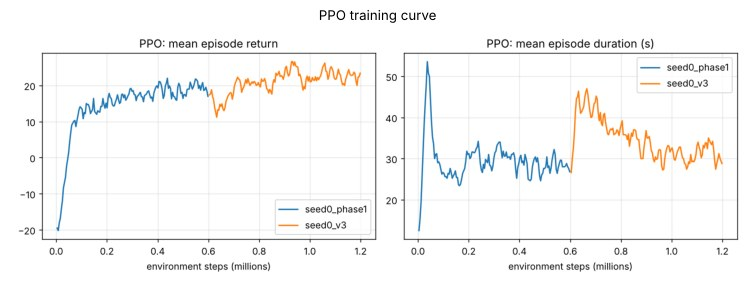

In [31]:
# Read the saved PPO training curve picture and show it
show(plt.imread("results/graphs/ppo_training_curve.png"), "PPO training curve", width=12)

✅ **Recap:** the policy is a small neural network trained with PPO. It maps
the obstacle map to one of 5 actions. Reward design matters a lot.

---
# 12. Safety shield: rules that can override the AI

🎯 **Learning goals:** understand why a learned policy needs a
**rule-based safety layer**.

🧠 **Concept**

A neural network is right *most* of the time, but we cannot prove it is
right *every* time. In safety-critical systems we therefore put simple,
checkable **rules** between the AI and the motors. Each action proposed by
the policy goes through the shield, and rules are checked **in priority
order**:

1. **Hard stop:** the robot's predicted path (an arc for turning actions)
   would hit any obstacle within the stopping distance → STOP (turning in
   place is still allowed).
2. **Person priority:** a person closer than 1.2 m → STOP; closer than
   2.5 m → SLOW.
3. **Uncertainty:** depth readings are unreliable (shiny wrap) → slow
   down or stop and re-check.
4. Otherwise → the policy's action is allowed.

Every override is written to a **decision log** with its reason, so a human
can audit it.

🧮 **The math: stopping distance**

$$d_{stop} = \underbrace{0.35\ \text{m}}_{\text{margin}} +
\underbrace{v \cdot t_{react}}_{\text{reaction (0.25 s)}} +
\underbrace{\frac{v^2}{2\,a_{brake}}}_{\text{braking } (3\ \text{m/s}^2)}$$

The braking part grows with $v^2$: **double the speed means four times the
braking distance**. That is why the shield also slows the robot down near
people and when depth is uncertain.

**👇 What the code below does**

Computes the stopping distance at several speeds with the shield's own
function.

In [32]:
# Create the safety shield
shield = SafetyShield()
# Try four speeds
for v in (0.3, 0.6, 1.0, 1.5):
    # Stopping distance = safety margin + reaction distance + braking distance
    print(f"speed {v:.1f} m/s  →  stopping distance {shield.stopping_distance(scene, v):.2f} m")

speed 0.3 m/s  →  stopping distance 0.44 m
speed 0.6 m/s  →  stopping distance 0.56 m
speed 1.0 m/s  →  stopping distance 0.77 m
speed 1.5 m/s  →  stopping distance 1.10 m


**👇 What the code below does**

**Scenario: a worker steps out in front of the robot.** The robot drives at
full speed (1.5 m/s), and a worker suddenly stands 1.5 m ahead. We let the
camera see the worker for two frames, then **force the policy's proposal to
GO** and ask the shield what it does with it.

policy proposed : GO
shield decided  : STOP  (speed cap 0.0)
reason          : Person in path at 0.7 m


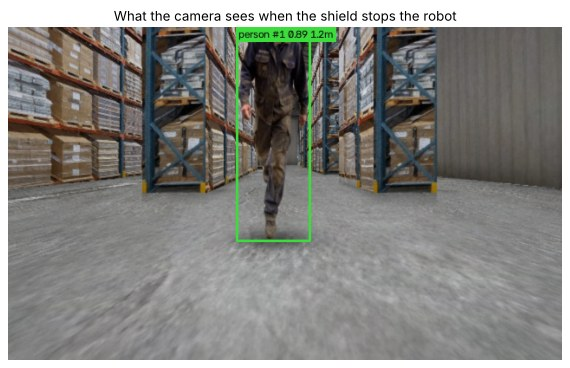

In [33]:
# A fresh, empty scene
risk = make_scene_env()
# The robot is driving at full speed (1.5 m/s)
risk.v = 1.5
# A worker suddenly stands 1.5 m in front of the robot
place(risk, PERSON, 1.5, 0.1, uid=990)
# Let the camera see the worker for two frames
for _ in range(2):
    # Render and process one camera frame
    risk._perceive()
# A fresh shield (with an empty decision log)
shield = SafetyShield()
# The policy proposes GO: ask the shield what it does with that
final, cap, reason = shield.filter(risk, GO)
# What the policy wanted
print("policy proposed : GO")
# What the shield decided, and the speed limit it set
print(f"shield decided  : {ACTIONS[final]}  (speed cap {cap})")
# Why it decided that
print(f"reason          : {reason}")
# Show what the camera sees at that moment
show(draw_overlay(risk.frame.rgb, risk.vision_result), "What the camera sees when the shield stops the robot", width=9)

🔎 **What to notice:** the shield overrides GO with **STOP** and writes down
why. In our evaluation this scripted "worker steps out" test was stopped in
**100 % of 50 scenes**.

✅ **Recap:** AI proposes, rules dispose. The shield makes collisions with
visible obstacles very unlikely, at the cost of some extra waiting.

---
# 13. Everything together: one full drive with the real-image camera

🎯 **Learning goals:** watch the complete **perception → decision → action**
loop run on its own.

The loop the robot runs every 0.2 s:

```python
obs = env.reset()
while not done:
    action = policy.act(obs)                       # PPO proposes
    action, cap, reason = shield.filter(env, action)   # shield checks
    obs, reward, terminated, truncated, info = env.step(action)
    # inside step(): render camera frame → YOLO → depth processing →
    #                fusion → tracking → new obstacle map
```

We use a **held-out** random warehouse (seed 10000, not used in training),
with the default random obstacles.

**👇 What the code below does**

Runs one complete episode with the real-image camera in the loop:

* at every step: policy → shield → `env.step()` (which renders the camera
  frame and runs the whole perception stack);
* every 4th step it stores a picture of the map plus the camera view for
  the animation;
* at the end it prints the result, the time, and the number of shield
  overrides.

In [34]:
# A new warehouse environment with the default random obstacles
drive = WarehouseEnv(EnvConfig())
# Attach the real-image camera and the detector
attach_real_camera(drive, detector=detector)
# A held-out warehouse (seed 10000 was never used in training)
obs, info = drive.reset(seed=10000)
# The trained policy and a fresh safety shield
policy, shield = NumpyPolicy(), SafetyShield()

# Stored pictures, total reward so far, and a stopwatch
frames, total_reward, t0 = [], 0.0, time.time()
# Drive until the episode ends
while True:
    # 1. The policy proposes an action from the obstacle map
    proposed = policy.act(obs, drive)
    # 2. The shield checks it (and may override it)
    action, cap, reason = shield.filter(drive, proposed)
    # 3. Execute it for 0.2 s; inside: camera frame → YOLO → depth processing → fusion → tracking
    obs, reward, terminated, truncated, info = drive.step(action)
    # Add up the reward
    total_reward += reward
    # Every 4th step (and at the very end) ...
    if drive.steps % 4 == 0 or terminated or truncated:
        # ... draw map + camera view + HUD, showing this step's decision
        img = render_frame(drive, decision=(ACTIONS[proposed], ACTIONS[action], reason), controller="PPO + safety shield", reward=total_reward)
        # ... and keep the step number with the picture
        frames.append((drive.steps, img))
    # Goal reached, collision, or time is up?
    if terminated or truncated:
        # Then leave the loop
        break

# Turn the result into a short sentence
outcome = "reached the goal ✓" if info["reached"] else (f"collision with {info['collision_with']} ✗" if info["collided"] else "time limit")
# Print the result and how long the robot drove
print(f"Result: {outcome} after {info['steps']} steps ({info['steps'] * 0.2:.0f} s of robot time)")
# Print the path length, the near misses and the shield overrides
print(f"Path length {info['path_length']:.1f} m, near misses {info['near_misses']}, shield overrides {shield.interventions}")
# Print how long the computer needed
print(f"Computed in {time.time() - t0:.0f} s on this CPU ({1000 * (time.time() - t0) / info['steps']:.0f} ms per step incl. rendering)")

Result: reached the goal ✓ after 79 steps (16 s of robot time)
Path length 21.5 m, near misses 0, shield overrides 1
Computed in 5 s on this CPU (59 ms per step incl. rendering)


**👇 What the code below does**

Shows four moments of the drive (start, two middle points, end). Each
picture contains the **map** (left) and the **camera view with detections,
depth image and HUD** (right).

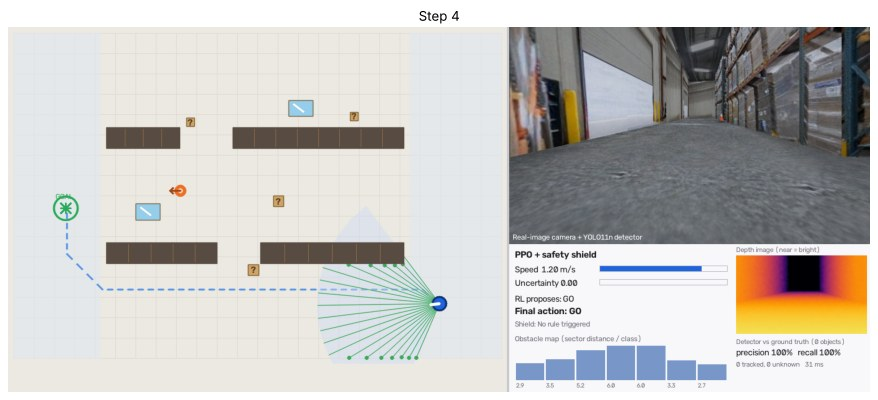

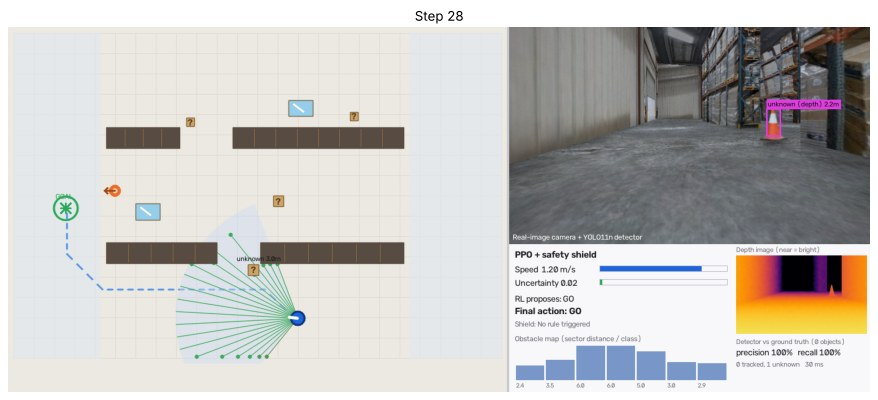

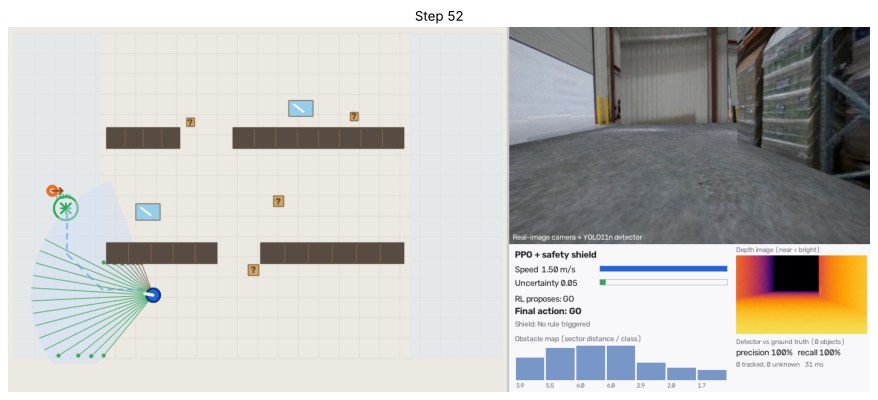

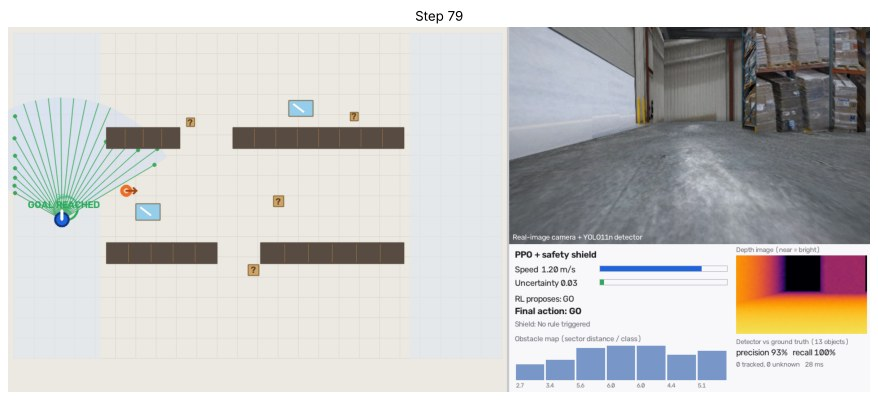

In [35]:
# Four evenly spread picture numbers: the start, two middle points, the end
pick = np.linspace(0, len(frames) - 1, 4).astype(int)
# Go through the four
for i in pick:
    # The step number and the picture
    step, img = frames[i]
    # Show the picture with its step number
    show(img, f"Step {step}", width=14)

**👇 What the code below does**

Turns the stored pictures into a small **animated GIF** in memory (frames
shrunk to 45 % and reduced to 128 colours to keep it light) and shows it in
the notebook. Play it in class to show the robot driving.

25 frames, 0.9 MB


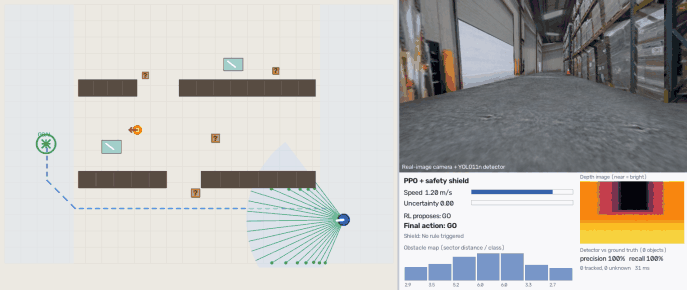

In [36]:
# An in-memory file for the GIF
gif = io.BytesIO()
# The frames of the animation
pil_frames = []
# Go through the stored pictures
for step, img in frames:
    # Shrink the picture to 45 % of its size
    small = cv2.resize(img, (int(img.shape[1] * 0.45), int(img.shape[0] * 0.45)), interpolation=cv2.INTER_AREA)
    # Turn it into a Pillow image with 128 colours (keeps the GIF small)
    pil_frames.append(Image.fromarray(small).quantize(colors=128))
# Repeat the last picture 5 times: a short pause at the end
pil_frames += [pil_frames[-1]] * 5
# Save all pictures as one looping GIF, 240 ms per picture
pil_frames[0].save(gif, format="GIF", save_all=True, append_images=pil_frames[1:], duration=240, loop=0, optimize=True)
# Print the number of pictures and the size of the GIF
print(f"{len(pil_frames)} frames, {gif.tell() / 1e6:.1f} MB")
# Show the animation in the notebook
display(IPImage(data=gif.getvalue(), format="gif"))

**👇 What the code below does**

Prints the **decision log**: every step where the shield changed the
policy's action, with its reason. This is how a safety engineer audits the
robot.

In [37]:
# Every decision where the shield changed the policy's action
overrides = [r for r in shield.log if r.proposed != r.final]
# How many overrides, out of how many decisions
print(f"{len(overrides)} overrides in {len(shield.log)} decisions:")
# Go through the first 12 overrides
for r in overrides[:12]:
    # Print the step, proposed action → final action, and the reason
    print(f"  step {r.step:3d}: {r.proposed:10s} → {r.final:10s}  {r.reason}")

1 overrides in 79 decisions:
  step  58: GO         → STOP        Person at 1.1 m


**👇 What the code below does**

Prints how well the camera perception did **during this drive**, scored
frame by frame against the simulator's ground truth by the `DetectionMeter`:

* the **raw detector** (YOLO boxes only);
* the **full stack** (after depth gates and tracking);
* the distance error of correct detections.

In [38]:
# The scores collected frame by frame during the drive
s = drive.vision_meter.summary()
# Overall scores of the raw detector and of the full perception stack
raw_all, stack_all = s["raw"]["all"], s["stack"]["all"]
# How many frames and objects were scored
print(f"frames scored: {s['frames']}, objects to find: {raw_all['objects']}")
# Precision and recall of the raw YOLO boxes
print(f"raw detector : precision {100 * raw_all['precision']:.0f}%  recall {100 * raw_all['recall']:.0f}%")
# Precision and recall after the depth gates and tracking
print(f"full stack   : precision {100 * stack_all['precision']:.0f}%  recall {100 * stack_all['recall']:.0f}%")
# If at least one object was matched ...
if s["range_mae_m"] is not None:
    # ... print the mean absolute distance error in centimetres
    print(f"distance error (mean absolute): {100 * s['range_mae_m']:.0f} cm")

frames scored: 80, objects to find: 13
raw detector : precision 93%  recall 100%
full stack   : precision 93%  recall 100%
distance error (mean absolute): 2 cm


🔎 **What to notice**

* The robot drives from start to goal on its own. The policy proposes, the
  shield checks, and the camera perception updates the obstacle map every
  frame. The decision log explains every override.
* Both the **raw detector** and the **full stack** reach high precision and
  recall on this drive. With the earlier **epoch-2** detector, the raw
  precision on this same drive was only **38 %**. Most of its false alarms
  were real parcels standing **on the rack shelves** (part of the rack, not
  obstacles in the aisle) and "persons" with an impossible size. The depth
  **"flat on the map" gate** and the **size gate** cleaned that up (to
  92 %). Training more removed most of those false alarms at the source
  (section 6), and the gates remain as a safety net.
* One drive is a small sample (a few objects over about 80 frames). The
  percentages move from drive to drive.

**Backup animations** (recorded earlier with the schematic camera; use them
if you cannot run the notebook live):

| Random warehouse | Worker steps out |
|---|---|
| ![random](../results/demo/demo_random.gif) | ![worker](../results/demo/demo_worker_step_out.gif) |
| **Fallen unknown boxes** | **Shiny stretch-wrapped pallets** |
| ![boxes](../results/demo/demo_unknown_boxes.gif) | ![reflective](../results/demo/demo_reflective.gif) |

---
# 14. Evaluation: how good is it?

🎯 **Learning goals:** read the evaluation honestly: what we measured, on
which data, and what the numbers mean.

🧠 **Concept: how we evaluate**

* **100 episodes per configuration**, on **held-out** random warehouses
  (seeds never used in training).
* **Success** = reached the goal. **Collision** = touched anything.
  **Time-out** = still driving after 90 s (safe, but not useful).
* **Ablation study:** we switch parts of the system off one at a time to see
  what each part contributes.

These 100-episode results use the **fast emulated perception** (the
detector is simulated with 80–97 % recall), because the RL training and the
large evaluations need millions of steps. The real-image camera is evaluated
separately at the end of this section.

**👇 What the code below does**

Loads the saved evaluation (`results/metrics/navigation_eval.json`) and
draws **success / collision / time-out rates** for the four controllers:
PPO with and without the shield, and a hand-written rule-based baseline
with and without the shield.

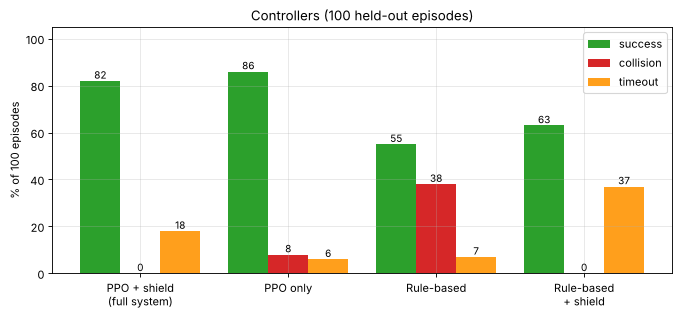

In [39]:
# Load the saved 100-episode evaluation
nav = json.load(open("results/metrics/navigation_eval.json"))
# Readable names for the four controllers
names = {"ppo_shield": "PPO + shield\n(full system)", "ppo": "PPO only", "rule": "Rule-based", "rule_shield": "Rule-based\n+ shield"}


# Function: bar chart of the success / collision / time-out rates
def outcome_chart(results, labels, title):
    # The configurations to show, in order
    keys = list(labels)
    # One x position per configuration
    x = np.arange(len(keys))
    # A new chart
    plt.figure(figsize=(10, 4))
    # Three bars per configuration: success (green), collision (red), time-out (orange)
    for j, (metric, col) in enumerate([("success_rate", "#2ca02c"), ("collision_rate", "#d62728"), ("timeout_rate", "#ff9f1c")]):
        # The values, in percent
        vals = [100 * results[k][metric] for k in keys]
        # Draw the bars, shifted to the left / centre / right
        plt.bar(x + (j - 1) * 0.27, vals, 0.27, color=col, label=metric.replace("_rate", ""))
        # Go through the bars to label them
        for xi, v in zip(x + (j - 1) * 0.27, vals):
            # Write the value just above the bar
            plt.text(xi, v + 1, f"{v:.0f}", ha="center", fontsize=9)
    # Configuration names under the bars
    plt.xticks(x, [labels[k] for k in keys])
    # Label of the y-axis
    plt.ylabel("% of 100 episodes")
    # The y-axis goes from 0 to 105 %
    plt.ylim(0, 105)
    # Chart title
    plt.title(title)
    # Legend
    plt.legend()
    # Show the chart
    plt.show()


# Draw the chart for the four controllers
outcome_chart(nav["controllers"], names, "Controllers (100 held-out episodes)")

🔎 **What to notice**

* **PPO beats the rule-based baseline** (82–86 % vs 55–63 % success): the
  learned policy steers around obstacles instead of just stopping.
* **The shield removes all collisions** (8 % → 0 % for PPO, 38 % → 0 % for
  the rules), at the price of more time-outs: the robot sometimes waits
  instead of squeezing past.
* In safety-critical robotics this trade-off is usually right: **a late
  delivery is better than an accident.**

**👇 What the code below does**

Draws the **ablation study**: the full system with perception parts removed
(detector only → + depth fusion → + uncertainty → + tracking).

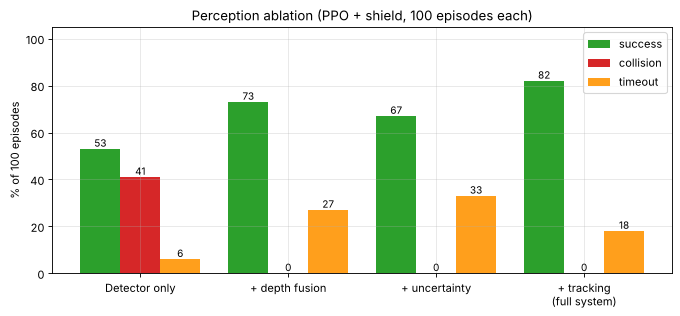

Collisions of 'detector only' by class: {'unknown': 41}


In [40]:
# Readable names for the four perception set-ups
abl_names = {"detector_only": "Detector only", "fusion": "+ depth fusion", "fusion_uncertainty": "+ uncertainty", "full": "+ tracking\n(full system)"}
# Draw the ablation chart with the same function
outcome_chart(nav["ablation"], abl_names, "Perception ablation (PPO + shield, 100 episodes each)")
# Which obstacles the detector-only robot crashed into
print("Collisions of 'detector only' by class:", nav["ablation"]["detector_only"]["collisions_by_class"])

🔎 **What to notice:** with the **detector only**, 41 % of the episodes end
in a collision, **all of them with unknown objects** the detector cannot
see. Adding **depth** brings collisions to **0 %**. Tracking then recovers
success by making the obstacle map stable. Each part earns its place.

**👇 What the code below does**

Draws two perception results from `results/metrics/perception_eval.json`:

* left: **obstacle recall**: what share of the obstacles within 5.5 m is
  reported at all (detector only vs. full fusion);
* right: the **uncertainty score** near normal vs. shiny stretch-wrapped
  pallets (histogram).

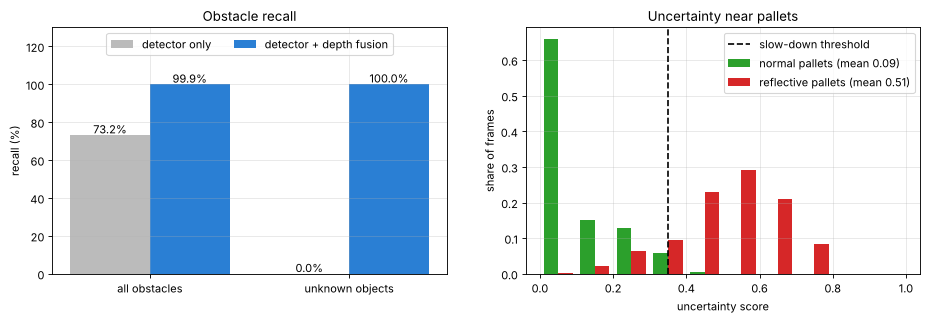

In [41]:
# Load the saved perception evaluation
per = json.load(open("results/metrics/perception_eval.json"))
# Two charts side by side
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
# The two groups of bars
labels = ["all obstacles", "unknown objects"]
# Recall of the detector alone: all obstacles, unknown objects
det_only = [per["obstacle_recall_detector_only"], per["unknown_box_recall_detector_only"]]
# Recall with depth fusion: all obstacles, unknown objects
full = [per["obstacle_recall_full"], per["unknown_box_recall_full"]]
# The x positions of the two groups
x = np.arange(2)
# Grey bars: detector only
a1.bar(x - 0.2, [100 * v for v in det_only], 0.4, color="#bbb", label="detector only")
# Blue bars: detector + depth fusion
a1.bar(x + 0.2, [100 * v for v in full], 0.4, color="#2a7fd4", label="detector + depth fusion")
# Go through the blue bars
for xi, v in zip(x, full):
    # Write the value just above the blue bar
    a1.text(xi + 0.2, 100 * v + 1, f"{100 * v:.1f}%", ha="center")
# Go through the grey bars
for xi, v in zip(x, det_only):
    # Write the value just above the grey bar
    a1.text(xi - 0.2, 100 * v + 1, f"{100 * v:.1f}%", ha="center")
# Group names under the bars
a1.set_xticks(x, labels)
# Leave room at the top for the legend
a1.set_ylim(0, 130)
# Label of the y-axis
a1.set_ylabel("recall (%)")
# Chart title
a1.set_title("Obstacle recall")
# Legend at the top
a1.legend(loc="upper center", ncol=2)
# The centres of the 10 histogram bins (0.05, 0.15, ..., 0.95)
bins = np.linspace(0, 1, 11)[:-1] + 0.05
# One histogram for normal pallets (green) and one for shiny pallets (red)
for name, col in [("normal pallets", "#2ca02c"), ("reflective pallets", "#d62728")]:
    # The saved histogram counts
    h = np.array(per["uncertainty"][name]["hist"], float)
    # Bars as a share of all frames, shifted a little so both colours are visible
    a2.bar(bins + (0.02 if "refl" in name else -0.02), h / h.sum(), 0.04, color=col, label=f"{name} (mean {per['uncertainty'][name]['mean']:.2f})")
# A dashed line: the shield's slow-down threshold
a2.axvline(0.35, color="k", ls="--", label="slow-down threshold")
# Label of the x-axis
a2.set_xlabel("uncertainty score")
# Label of the y-axis
a2.set_ylabel("share of frames")
# Chart title
a2.set_title("Uncertainty near pallets")
# Legend
a2.legend()
# Show both charts
plt.show()

🔎 **What to notice:** fusion lifts obstacle recall from 73 % to **99.9 %**
(unknown objects: 0 % → 100 %). The uncertainty score is clearly higher near
**stretch-wrapped** pallets, so the robot slows down exactly where its depth
sensor is least reliable.

### Live mini-benchmark (run it in class)

🧠 Numbers in a file are less convincing than numbers you produce in front
of the class. The next cell runs fresh episodes **right now**:

* **20 episodes** with the fast emulated perception: PPO + shield vs. the
  rule-based baseline + shield;
* **3 episodes** with the **real-image camera** (YOLO on every frame). Each
  takes 10–30 s; set `N_REAL = 0` to skip them.

The seeds start at 10000 (held-out).

**👇 What the code below does**

* `run_episodes()` drives a list of seeds with a given controller and
  camera, and counts successes, collisions and time-outs.
* Runs the three experiments described above and prints a small results
  table with the time each one took.

In [42]:
# Number of episodes: with the fast emulated perception, and with the real-image camera
N_EMULATED, N_REAL = 20, 3


# Function: drive a list of seeds and count how the episodes end
def run_episodes(seeds, controller="ppo", real_camera=False):
    # A new environment with the default random obstacles
    env = WarehouseEnv(EnvConfig())
    # If asked, use the real-image camera (YOLO on every frame) ...
    if real_camera:
        # ... by attaching the camera and the detector
        attach_real_camera(env, detector=detector)
    # The PPO policy, or the rule-based baseline
    pol = NumpyPolicy() if controller == "ppo" else RuleBasedController()
    # A safety shield
    sh = SafetyShield()
    # Counters for the three possible outcomes
    out = {"reached": 0, "collided": 0, "timeout": 0}
    # One episode per seed
    for seed in seeds:
        # Build the warehouse of this seed
        obs, _ = env.reset(seed=seed)
        # Clear the shield's memory and log
        sh.reset()
        # Drive until the episode ends
        while True:
            # The policy proposes, the shield checks
            a, _, _ = sh.filter(env, pol.act(obs, env))
            # Execute the action for 0.2 s
            obs, _, term, trunc, inf = env.step(a)
            # Is the episode over?
            if term or trunc:
                # Then leave the loop
                break
        # Which of the three outcomes happened
        key = "reached" if inf["reached"] else ("collided" if inf["collided"] else "timeout")
        # Count it
        out[key] += 1
    # Give the counts back
    return out


# The list of experiments: (name, seeds, controller, real camera?)
experiments = []
# Experiment 1: PPO + shield with the fast emulated perception
experiments.append(("PPO + shield, emulated perception", range(10000, 10000 + N_EMULATED), "ppo", False))
# Experiment 2: rule-based baseline + shield with the fast emulated perception
experiments.append(("Rule-based + shield, emulated", range(10000, 10000 + N_EMULATED), "rule", False))
# Experiment 3: PPO + shield with the real-image camera in the loop
experiments.append(("PPO + shield, REAL-IMAGE camera", range(10000, 10000 + N_REAL), "ppo", True))
# The table header
print(f"{'experiment':36s} {'episodes':>8s} {'reached':>8s} {'collided':>9s} {'timeout':>8s} {'time':>6s}")
# Run the experiments one by one
for name, seeds, ctrl, real in experiments:
    # An experiment with 0 episodes (for example N_REAL = 0) ...
    if len(seeds) == 0:
        # ... is skipped
        continue
    # Start a stopwatch
    t0 = time.time()
    # Run the episodes
    r = run_episodes(seeds, ctrl, real)
    # Print one table row with the counts and the time it took
    print(f"{name:36s} {len(seeds):8d} {r['reached']:8d} {r['collided']:9d} {r['timeout']:8d} {time.time() - t0:5.0f}s")

experiment                           episodes  reached  collided  timeout   time


PPO + shield, emulated perception          20       16         0        4     7s


Rule-based + shield, emulated              20       13         0        7    10s


PPO + shield, REAL-IMAGE camera             3        3         0        0    36s


🔎 **What to notice:** with only 20 episodes the numbers jump around a bit
(each episode is 5 %), but the pattern matches the 100-episode study. The
3 real-camera episodes show that the **same policy works with real YOLO
detections** in the loop. They are a demonstration, not a benchmark; the
larger real-camera test follows in section 15.

---
# 15. Honest limitations and future work

🎯 **Learning goals:** a good engineer reports what does **not** work yet.

**1. Navigation with the real-image camera is harder than with the emulated
perception, and better detection did not fix it.**
Over **40 held-out episodes** with the real-image camera in the loop (seeds
10000–10039, PPO + shield, `scripts/eval_real_image_sim.py`), the robot

| Detector | Reached goal | Collision | Time-out |
|---|---|---|---|
| epoch 2 | 62.5 % | 10 % | 27.5 % |
| epoch 8 | 62.5 % | 10 % | 27.5 % |

compared with 82 % / 0 % / 18 % with the emulated perception. The detector
got much better (false alarms 1,637 → 255, recall 91 % → 99 %), yet the
driving results stayed exactly the same. **So the remaining failures are not
detection failures.** The policy was trained on the emulated perception and
has never "seen" the camera pipeline during training.

* **The collisions are almost all with pallets.** In the case we inspected
  frame by frame, the robot was **turning next to a pallet**: the pallet slid
  out of the 120° field of view (a **blind spot beside the robot**) and the
  robot's side clipped its corner.
* **Time-outs:** the robot often stops in front of a pallet or an unknown
  object and waits (the shield blocks the way), instead of driving around it.

❓ **Ask the class:** *We improved the detector a lot, but the robot does
not crash less. What does that tell us about where to work next?*

**2. It is still a simulation.** The images are real photos, but they are
put together as flat cut-outs. Real cameras add lighting changes, real
reflections and motion. No physical-robot tests have been done yet.

**3. Depth on shiny stretch wrap** is modelled as "see-through" bands. The
uncertainty score makes the robot slow down there, but it does not repair
the depth.

### Next steps

* **Fine-tune the policy with the real-image camera in the loop**, so it
  learns how the camera pipeline behaves. Detection itself is now strong
  (98.9 % mAP@50 while driving), so the next gains are in the decisions.
* **Remember obstacles that leave the field of view** for longer (a local
  occupancy map), against the blind-spot collisions.
* **Fill depth holes** inside objects (stretch wrap) and make every cut-out
  cover the object's full footprint.
* **Train on the LOCO dataset** (real logistics photos: pallets, forklifts,
  small load carriers, stillages) and test on a real robot.

---
# 16. Summary

| Step | Technique | Course topic |
|---|---|---|
| Camera images | real photo cut-outs + perspective rectification, pinhole model | image formation |
| Detection | YOLO11n, letterbox, IoU, NMS, transfer learning, robot-view fine-tuning (8 epochs) | deep learning / CNNs |
| Depth processing | map background subtraction, adaptive threshold, morphology, range scan | classic image processing |
| Fusion | depth + ground-plane geometry, physical gates | sensor fusion |
| Tracking | Kalman filter on the floor plane, ByteTrack-style association | video processing |
| Decision | PPO policy on a 47-number obstacle map | reinforcement learning |
| Safety | rule-based shield with decision log | safe AI |

**Main messages**

1. A detector alone is **not enough**: it is blind to unknown objects. Depth
   processing fixes that (collisions 41 % → 0 % in the ablation).
2. **Video processing (tracking)** makes perception stable and gives
   velocities.
3. **Reinforcement learning** learns smooth avoidance behaviour; a **safety
   shield** guarantees the hard rules.
4. Honest evaluation on **held-out** data shows both the strengths and what
   still needs work.

## ❓ Discussion questions for the class

1. The detector reaches about 88 % mAP@50. Why can the whole robot still be
   much safer than that number suggests? (Hint: depth, tracking, shield.)
2. What would happen if the robot's position (localisation) were wrong by
   50 cm? Which part of the pipeline would suffer first? (Hint: the expected
   depth image from the map.)
3. Why do we test on **held-out** seeds and cut-outs? What would happen to
   the numbers if we tested on the training data?
4. The shield removes collisions but increases time-outs. How would *you*
   balance safety and productivity in a real warehouse?
5. How could we teach the robot to deal with the blind spot beside it?

## 📚 References

* Jocher et al., *Ultralytics YOLO11* (2024). https://docs.ultralytics.com
* Schulman et al., *Proximal Policy Optimization Algorithms* (2017). arXiv:1707.06347
* Zhang et al., *ByteTrack: Multi-Object Tracking by Associating Every Detection Box* (ECCV 2022)
* Kalman, *A New Approach to Linear Filtering and Prediction Problems* (1960)
* Dwibedi et al., *Cut, Paste and Learn: Surprisingly Easy Synthesis for Instance Detection* (ICCV 2017)
* Mayershofer et al., *LOCO: Logistics Objects in Context* (ICMLA 2020)
* Datasets: Ultralytics Construction-PPE (CC BY 4.0) and Package-seg; see
  `assets/sim/ATTRIBUTION.md`.

---
*All numbers in this notebook are **simulation** results on held-out data,
not physical-robot results.*